In [1]:
import pandas as pd

In [5]:
path_date = './DADOS/Dados_corrigidos_pelo_filtro'
df_full = pd.read_parquet(path_date)

df_full.index = pd.date_range(
    start="2019-01-01 00:00:00",
    periods=len(df_full),
    freq="min")

df_full.index.name = "Time"

print("Primeiro instante:", df_full.index.min())
print("Último instante:  ", df_full.index.max())
print("Número de linhas:  ", len(df_full))

Primeiro instante: 2019-01-01 00:00:00
Último instante:   2019-12-31 23:59:00
Número de linhas:   525600


In [19]:
# ============================================================
# 2. PARÂMETROS DO MODELO PASSA-BAIXAS
# ============================================================

import numpy as np

AREA_USINA = 5.15       # hectares
K_FILTRO = 2.136        # kW / (W/m²)

fc = 0.021 * AREA_USINA**(-0.5)
tau = 1 / (2 * np.pi * fc)

fator_exp_60s = np.exp(-60 / tau)
alpha_60s = 1 - fator_exp_60s

print(f"fc              = {fc:.6f} Hz")
print(f"tau             = {tau:.4f} s")
print(f"exp(-60/tau)    = {fator_exp_60s:.6f}")
print(f"1-exp(-60/tau)  = {alpha_60s:.6f}")

fc              = 0.009254 Hz
tau             = 17.1990 s
exp(-60/tau)    = 0.030545
1-exp(-60/tau)  = 0.969455


In [13]:
# ============================================================
# 3. CENÁRIO DE TESTE: 03/01/2019 - 10:00 às 12:00
# ============================================================

inicio_teste = pd.Timestamp("2019-01-03 10:00:00")
fim_teste    = pd.Timestamp("2019-01-03 12:00:00")

# Intervalo [10:00, 12:00), ou seja, exatamente 120 minutos
mask_teste = (
    (df_full.index >= inicio_teste) &
    (df_full.index < fim_teste)
)

df_teste_original = df_full.loc[mask_teste].copy()

print("Número de amostras:", len(df_teste_original))
print("NaNs:")
print(df_teste_original[["P", "G"]].isna().sum())
print("P <= 0:", (df_teste_original["P"] <= 0).sum())
print("G <= 0:", (df_teste_original["G"] <= 0).sum())

display(df_teste_original.head())

Número de amostras: 120
NaNs:
P    0
G    0
dtype: int64
P <= 0: 0
G <= 0: 0


,P,G,Zenith,P_Corrigido
Time,,,,
2019-01-03 10:00:00,1781.9,823.29,28.772886,1781.9
2019-01-03 10:01:00,1787.0,825.15,28.561789,1787.0
2019-01-03 10:02:00,1796.8,827.51,28.351122,1796.8
2019-01-03 10:03:00,1797.8,827.44,28.140896,1797.8
2019-01-03 10:04:00,1802.1,829.90,27.931121,1802.1


In [8]:
# ============================================================
# 4. CRIAÇÃO DA LACUNA ARTIFICIAL
# ============================================================

df_sim = df_full.copy()

# Guarda a potência real antes de criar a falha
df_sim["P_Real"] = df_sim["P"].copy()

# Cria artificialmente a falha de potência
df_sim.loc[mask_teste, "P"] = 0.0

print("Potência original no intervalo:")
display(
    df_sim.loc[mask_teste, ["P_Real", "P", "G"]].head()
)

Potência original no intervalo:


,P_Real,P,G
Time,,,
2019-01-03 10:00:00,1781.9,0.0,823.29
2019-01-03 10:01:00,1787.0,0.0,825.15
2019-01-03 10:02:00,1796.8,0.0,827.51
2019-01-03 10:03:00,1797.8,0.0,827.44
2019-01-03 10:04:00,1802.1,0.0,829.90


In [9]:
# ============================================================
# 5. FUNÇÃO DE RECONSTRUÇÃO PELO FILTRO PASSA-BAIXAS
# ============================================================

def reconstruir_intervalo_filtro(
    df,
    inicio,
    fim,
    k=K_FILTRO,
    tau=tau,
    col_p="P",
    col_g="G"
):
    
    df_out = df.copy()
    df_out["P_Filtro"] = np.nan

    mask = (
        (df_out.index >= inicio) &
        (df_out.index < fim)
    )

    indices_falha = df_out.index[mask]

    if len(indices_falha) == 0:
        raise ValueError("Nenhuma amostra encontrada no intervalo.")

    # --------------------------------------------------------
    # Estado imediatamente anterior à falha
    # --------------------------------------------------------
    
    idx_inicio = indices_falha[0]
    pos_inicio = df_out.index.get_loc(idx_inicio)

    if pos_inicio == 0:
        raise ValueError("Não existe amostra anterior para inicializar o filtro.")

    idx_anterior = df_out.index[pos_inicio - 1]

    p_anterior = df_out.loc[idx_anterior, col_p]
    g_anterior = df_out.loc[idx_anterior, col_g]
    t_anterior = idx_anterior

    # --------------------------------------------------------
    # Reconstrução recursiva
    # --------------------------------------------------------

    for t_atual in indices_falha:

        g_atual = df_out.loc[t_atual, col_g]

        delta_t = (t_atual - t_anterior).total_seconds()

        fator_exp = np.exp(-delta_t / tau)
        alfa = 1 - fator_exp

        # Irradiância média no intervalo
        g_medio = (g_anterior + g_atual) / 2

        # Solução analítica da EDO
        p_estimado = (
            p_anterior * fator_exp
            +
            k * g_medio * alfa
        )

        df_out.loc[t_atual, "P_Filtro"] = p_estimado

        # Atualização dos estados
        p_anterior = p_estimado
        g_anterior = g_atual
        t_anterior = t_atual

    return df_out

In [10]:
df_sim = reconstruir_intervalo_filtro(
    df=df_sim,
    inicio=inicio_teste,
    fim=fim_teste
)

In [11]:
display(
    df_sim.loc[
        mask_teste,
        ["P_Real", "P", "G", "P_Filtro"]
    ].head(10)
)

,P_Real,P,G,P_Filtro
Time,,,,
2019-01-03 10:00:00,1781.9,0.0,823.29,1730.799450
2019-01-03 10:01:00,1787.0,0.0,825.15,1735.654356
2019-01-03 10:02:00,1796.8,0.0,827.51,1740.110578
2019-01-03 10:03:00,1797.8,0.0,827.44,1742.584407
2019-01-03 10:04:00,1802.1,0.0,829.90,1745.099768
2019-01-03 10:05:00,1795.7,0.0,827.31,1745.043891
2019-01-03 10:06:00,1799.0,0.0,826.17,1741.234464
2019-01-03 10:07:00,1801.4,0.0,831.62,1745.517911
2019-01-03 10:08:00,1808.2,0.0,836.25,1755.938779


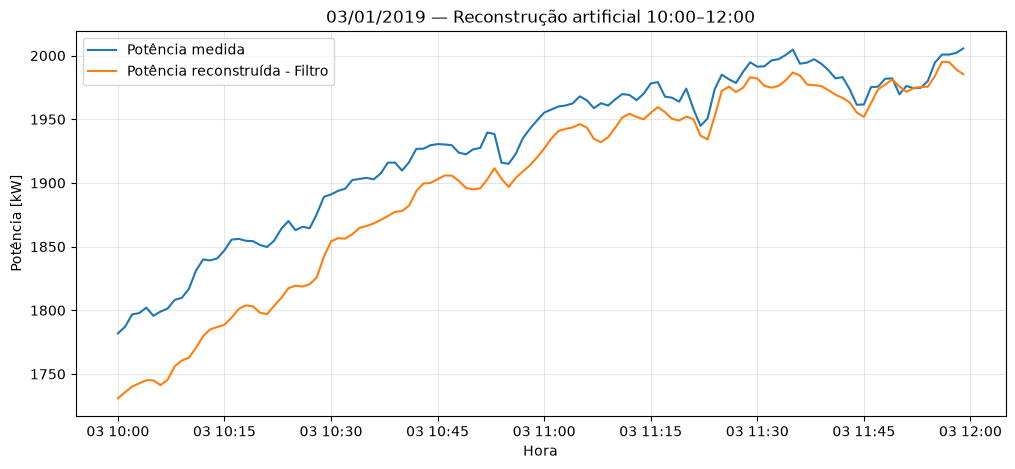

In [12]:
import matplotlib.pyplot as plt

df_comp = df_sim.loc[mask_teste].copy()

plt.figure(figsize=(12, 5))

plt.plot(
    df_comp.index,
    df_comp["P_Real"],
    label="Potência medida"
)

plt.plot(
    df_comp.index,
    df_comp["P_Filtro"],
    label="Potência reconstruída - Filtro"
)

plt.xlabel("Hora")
plt.ylabel("Potência [kW]")
plt.title("03/01/2019 — Reconstrução artificial 10:00–12:00")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [14]:
# ============================================================
# 6. FUNÇÃO DE MÉTRICAS
# ============================================================

from sklearn.metrics import r2_score

def calcular_metricas(medido, estimado):
    
    # Remove qualquer NaN eventualmente existente
    mask = medido.notna() & estimado.notna()

    medido = medido.loc[mask]
    estimado = estimado.loc[mask]

    erro = estimado - medido
    media_medida = medido.mean()

    RMSE = np.sqrt(np.mean(erro**2))

    nRMSE = 100 * RMSE / media_medida
    nMAE  = 100 * np.mean(np.abs(erro)) / media_medida
    nMBE  = 100 * np.mean(erro) / media_medida

    R2 = r2_score(medido, estimado)

    STDratio = estimado.std() / medido.std()

    return {
        "N": len(medido),
        "P_media_kW": media_medida,
        "RMSE_kW": RMSE,
        "nRMSE_%": nRMSE,
        "nMAE_%": nMAE,
        "nMBE_%": nMBE,
        "R2": R2,
        "STDratio": STDratio
    }

In [15]:
metricas_0301 = calcular_metricas(
    df_comp["P_Real"],
    df_comp["P_Filtro"]
)

pd.Series(metricas_0301)

N              120.000000
P_media_kW    1927.428333
RMSE_kW         32.988309
nRMSE_%          1.711519
nMAE_%           1.460876
nMBE_%          -1.454903
R2               0.710934
STDratio         1.260408
dtype: float64

In [21]:
# ============================================================
# 7. TESTE COM O K ÓTIMO DO DIA 03/01
# ============================================================

K_0301_ARTIGO = 2.136

df_sim_k_otimo = reconstruir_intervalo_filtro(
    df=df_sim,
    inicio=inicio_teste,
    fim=fim_teste,
    k=K_0301_ARTIGO,
    tau=tau
)

df_comp_k_otimo = df_sim_k_otimo.loc[mask_teste].copy()

metricas_0301_k_otimo = calcular_metricas(
    df_comp_k_otimo["P_Real"],
    df_comp_k_otimo["P_Filtro"]
)

pd.Series(metricas_0301_k_otimo)

N              120.000000
P_media_kW    1927.428333
RMSE_kW         18.446431
nRMSE_%          0.957049
nMAE_%           0.810404
nMBE_%          -0.051472
R2               0.909614
STDratio         1.278599
dtype: float64

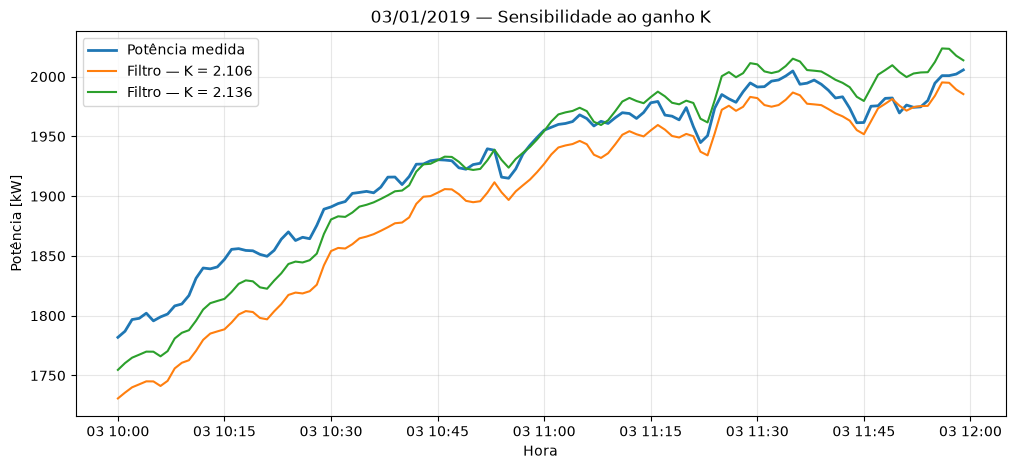

In [18]:
plt.figure(figsize=(12, 5))

plt.plot(
    df_comp.index,
    df_comp["P_Real"],
    label="Potência medida",
    linewidth=2
)

plt.plot(
    df_comp.index,
    df_comp["P_Filtro"],
    label="Filtro — K = 2.106"
)

plt.plot(
    df_comp_k_otimo.index,
    df_comp_k_otimo["P_Filtro"],
    label="Filtro — K = 2.136"
)

plt.xlabel("Hora")
plt.ylabel("Potência [kW]")
plt.title("03/01/2019 — Sensibilidade ao ganho K")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [22]:
# ============================================================
# 8. COMPARAÇÃO: K ÓTIMO DO DIA vs K GLOBAL
# ============================================================

K_GLOBAL = 2.106
K_0301_ARTIGO = 2.136

In [23]:
df_sim_k_global = reconstruir_intervalo_filtro(
    df=df_sim,
    inicio=inicio_teste,
    fim=fim_teste,
    k=K_GLOBAL,
    tau=tau
)

df_comp_k_global = df_sim_k_global.loc[mask_teste].copy()

In [24]:
metricas_0301_k_global = calcular_metricas(
    df_comp_k_global["P_Real"],
    df_comp_k_global["P_Filtro"]
)

pd.Series(metricas_0301_k_global)

N              120.000000
P_media_kW    1927.428333
RMSE_kW         32.988309
nRMSE_%          1.711519
nMAE_%           1.460876
nMBE_%          -1.454903
R2               0.710934
STDratio         1.260408
dtype: float64

In [25]:
comparacao_0301 = pd.DataFrame({
    "K ótimo do dia (2.136)": metricas_0301_k_otimo,
    "K global (2.106)": metricas_0301_k_global
}).T

comparacao_0301

,N,P_media_kW,RMSE_kW,nRMSE_%,nMAE_%,nMBE_%,R2,STDratio
K ótimo do dia (2.136),120.0,1927.428333,18.446431,0.957049,0.810404,-0.051472,0.909614,1.278599
K global (2.106),120.0,1927.428333,32.988309,1.711519,1.460876,-1.454903,0.710934,1.260408


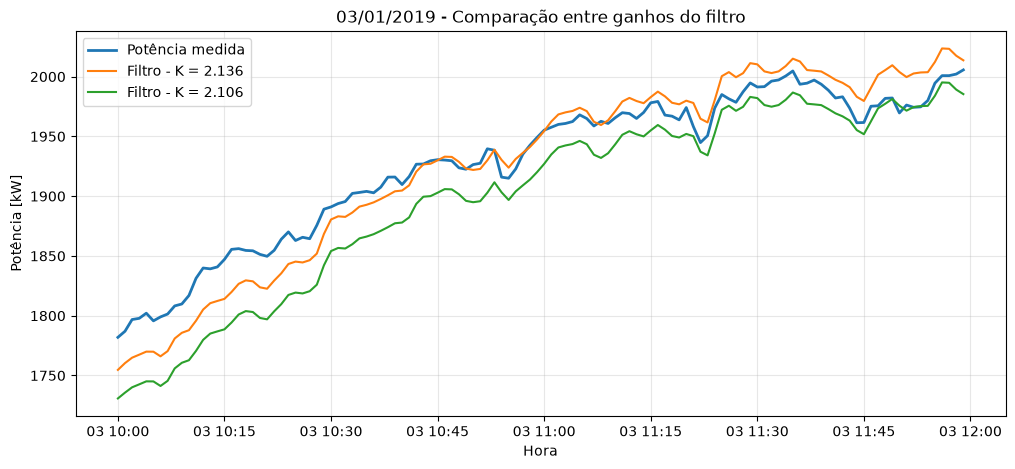

In [26]:
plt.figure(figsize=(12, 5))

plt.plot(
    df_comp_k_otimo.index,
    df_comp_k_otimo["P_Real"],
    label="Potência medida",
    linewidth=2
)

plt.plot(
    df_comp_k_otimo.index,
    df_comp_k_otimo["P_Filtro"],
    label="Filtro - K = 2.136"
)

plt.plot(
    df_comp_k_global.index,
    df_comp_k_global["P_Filtro"],
    label="Filtro - K = 2.106"
)

plt.xlabel("Hora")
plt.ylabel("Potência [kW]")
plt.title("03/01/2019 - Comparação entre ganhos do filtro")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [33]:
# ============================================================
# 9. DIAS DE CALIBRAÇÃO INFORMADOS PELO JOÃO
# ============================================================

K_GLOBAL = 2.106

DIAS_JOAO = pd.to_datetime([
    "2019-03-16",
    "2019-04-24",
    "2019-05-04",
    "2019-05-05",
    "2019-05-06",
    "2019-05-07",
    "2019-05-10",
    "2019-05-24",
    "2019-05-25",
    "2019-05-26",
    "2019-06-01",
    "2019-06-05",
    "2019-07-16",
    "2019-07-17",
    "2019-07-19",
    "2019-08-01",
    "2019-08-02",
    "2019-08-22",
    "2019-09-15",
    "2019-09-19",
    "2019-09-20"
])

print("Número de dias:", len(DIAS_JOAO))

Número de dias: 21


In [34]:
# ============================================================
# 10. AVALIAÇÃO DO FILTRO EM UM DIA COMPLETO
# ============================================================

def avaliar_dia_filtro(
    df,
    data,
    k=K_GLOBAL,
    tau=tau,
    g_min=300
):
    
    data = pd.Timestamp(data).normalize()

    inicio_dia = data
    fim_dia = data + pd.Timedelta(days=1)

    # Dados originais do dia
    df_dia = df.loc[
        (df.index >= inicio_dia) &
        (df.index < fim_dia)
    ].copy()

    # --------------------------------------------------------
    # Pontos que servirão para avaliação
    # --------------------------------------------------------
    
    mask_validos = (
        df_dia["P"].notna() &
        df_dia["G"].notna() &
        (df_dia["P"] > 0) &
        (df_dia["G"] >= g_min)
    )

    if mask_validos.sum() < 2:
        return None, None

    indices_validos = df_dia.index[mask_validos]

    inicio_falha = indices_validos[0]
    ultimo_instante = indices_validos[-1]
    fim_falha = ultimo_instante + pd.Timedelta(minutes=1)

    # Incluímos um minuto anterior para fornecer
    # a condição inicial P(t0)
    inicio_janela = inicio_falha - pd.Timedelta(minutes=1)

    df_sim_dia = df.loc[
        inicio_janela:ultimo_instante
    ].copy()

    # Guarda a verdade
    df_sim_dia["P_Real"] = df_sim_dia["P"].copy()

    # --------------------------------------------------------
    # Criação da falha artificial durante o período inteiro
    # --------------------------------------------------------

    mask_falha = (
        (df_sim_dia.index >= inicio_falha) &
        (df_sim_dia.index < fim_falha)
    )

    df_sim_dia.loc[mask_falha, "P"] = 0.0

    # --------------------------------------------------------
    # Reconstrução
    # --------------------------------------------------------

    df_rec = reconstruir_intervalo_filtro(
        df=df_sim_dia,
        inicio=inicio_falha,
        fim=fim_falha,
        k=k,
        tau=tau
    )

    # --------------------------------------------------------
    # Pontos realmente utilizados nas métricas
    # --------------------------------------------------------

    mask_avaliacao = (
        (df_rec.index >= inicio_falha) &
        (df_rec.index < fim_falha) &
        df_rec["P_Real"].notna() &
        df_rec["P_Filtro"].notna() &
        df_rec["G"].notna() &
        (df_rec["P_Real"] > 0) &
        (df_rec["G"] >= g_min)
    )

    df_comp = df_rec.loc[
        mask_avaliacao,
        ["P_Real", "P_Filtro", "G"]
    ].copy()

    if len(df_comp) < 2:
        return None, None

    metricas = calcular_metricas(
        df_comp["P_Real"],
        df_comp["P_Filtro"]
    )

    metricas["Data"] = data.date()

    df_comp["Data"] = data.date()

    return metricas, df_comp

In [35]:
# ============================================================
# 11. EXECUÇÃO DOS 21 DIAS
# ============================================================

resultados_dias = []
comparacoes_dias = []

for data in DIAS_JOAO:

    metricas, df_comp_dia = avaliar_dia_filtro(
        df=df_full,
        data=data,
        k=K_GLOBAL,
        tau=tau,
        g_min=300
    )

    if metricas is not None:
        resultados_dias.append(metricas)
        comparacoes_dias.append(df_comp_dia)

df_metricas_21 = pd.DataFrame(resultados_dias)

df_metricas_21 = df_metricas_21.set_index("Data")

df_metricas_21

,N,P_media_kW,RMSE_kW,nRMSE_%,nMAE_%,nMBE_%,R2,STDratio
Data,,,,,,,,
2019-03-16,541,1618.024030,88.557303,5.473176,3.374322,0.043095,0.964431,1.052124
2019-04-24,464,1748.074784,100.335630,5.739779,3.294645,-1.089934,0.947179,1.053914
2019-05-04,532,1665.452444,70.168223,4.213163,2.748952,-0.773110,0.975200,1.046362
2019-05-05,543,1654.891897,50.440678,3.047974,2.333085,-1.085805,0.987422,1.051718
2019-05-06,548,1652.112591,43.700123,2.645106,2.363795,-0.599512,0.990487,1.063111
2019-05-07,537,1640.107449,46.171206,2.815133,2.414108,-0.641276,0.988371,1.067040
2019-05-10,498,1588.945783,123.372472,7.764423,4.219775,-0.554143,0.933929,1.028580
2019-05-24,514,1584.490661,60.901792,3.843620,2.496803,-1.042182,0.978941,1.041957
2019-05-25,524,1599.646183,38.979801,2.436776,2.177129,-0.967635,0.990845,1.061663


In [36]:
# ============================================================
# 12. MÉTRICAS CONSOLIDADAS DOS 21 DIAS
# ============================================================

df_comp_21 = pd.concat(
    comparacoes_dias,
    axis=0
)

metricas_filtro_21 = calcular_metricas(
    df_comp_21["P_Real"],
    df_comp_21["P_Filtro"]
)

pd.Series(metricas_filtro_21)

N             10711.000000
P_media_kW     1618.890104
RMSE_kW          71.409934
nRMSE_%           4.411043
nMAE_%            2.735269
nMBE_%           -0.712940
R2                0.975300
STDratio          1.047027
dtype: float64

In [37]:
# ============================================================
# 13. DIAGNÓSTICO DAS MÉTRICAS DIA A DIA
# ============================================================

colunas_exibir = [
    "N",
    "P_media_kW",
    "RMSE_kW",
    "nRMSE_%",
    "nMAE_%",
    "nMBE_%",
    "R2",
    "STDratio"
]

df_metricas_21[colunas_exibir].sort_values(
    "nRMSE_%",
    ascending=False
)

,N,P_media_kW,RMSE_kW,nRMSE_%,nMAE_%,nMBE_%,R2,STDratio
Data,,,,,,,,
2019-07-19,159,860.644025,89.112263,10.354137,8.208415,-6.623522,0.669708,0.944049
2019-05-10,498,1588.945783,123.372472,7.764423,4.219775,-0.554143,0.933929,1.028580
2019-06-01,532,1570.421429,120.681801,7.684676,4.349382,-0.472147,0.929822,1.031670
2019-08-02,506,1613.658300,103.199388,6.395368,3.615359,-1.298202,0.950703,1.024333
2019-09-19,531,1637.280603,101.339644,6.189510,3.589295,0.244239,0.953795,1.036323
2019-04-24,464,1748.074784,100.335630,5.739779,3.294645,-1.089934,0.947179,1.053914
2019-03-16,541,1618.024030,88.557303,5.473176,3.374322,0.043095,0.964431,1.052124
2019-05-04,532,1665.452444,70.168223,4.213163,2.748952,-0.773110,0.975200,1.046362
2019-08-01,537,1615.341341,65.479118,4.053578,2.346248,-1.351625,0.977947,1.039130


In [38]:
# Resumo estatístico dos 21 dias

df_metricas_21[
    ["RMSE_kW", "nRMSE_%", "nMAE_%", "nMBE_%", "R2", "STDratio"]
].describe()

,RMSE_kW,nRMSE_%,nMAE_%,nMBE_%,R2,STDratio
count,21.000000,21.000000,21.000000,21.000000,21.000000,21.000000
mean,66.723704,4.328191,2.968093,-0.957098,0.960556,1.041919
std,29.440519,2.272716,1.409559,1.393884,0.069670,0.024878
min,34.967269,2.194313,1.872642,-6.623522,0.669708,0.944049
25%,39.058810,2.436776,2.177129,-1.085805,0.953795,1.039130
50%,58.073134,3.418414,2.414108,-0.773110,0.983102,1.047644
75%,89.112263,5.739779,3.374322,-0.554143,0.990845,1.052124
max,123.372472,10.354137,8.208415,0.335725,0.993254,1.067040


In [39]:
# ============================================================
# 14. FUNÇÃO PARA VISUALIZAR UM DIA
# ============================================================

def plotar_comparacao_dia(data, comparacoes_dias):

    data = pd.Timestamp(data).date()

    encontrados = [
        df for df in comparacoes_dias
        if df["Data"].iloc[0] == data
    ]

    if len(encontrados) == 0:
        print(f"Dia {data} não encontrado.")
        return

    df_dia = encontrados[0]

    plt.figure(figsize=(12, 5))

    plt.plot(
        df_dia.index,
        df_dia["P_Real"],
        label="Potência medida",
        linewidth=2
    )

    plt.plot(
        df_dia.index,
        df_dia["P_Filtro"],
        label="Potência reconstruída - Filtro"
    )

    plt.xlabel("Hora")
    plt.ylabel("Potência [kW]")
    plt.title(f"Comparação - {data}")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.show()

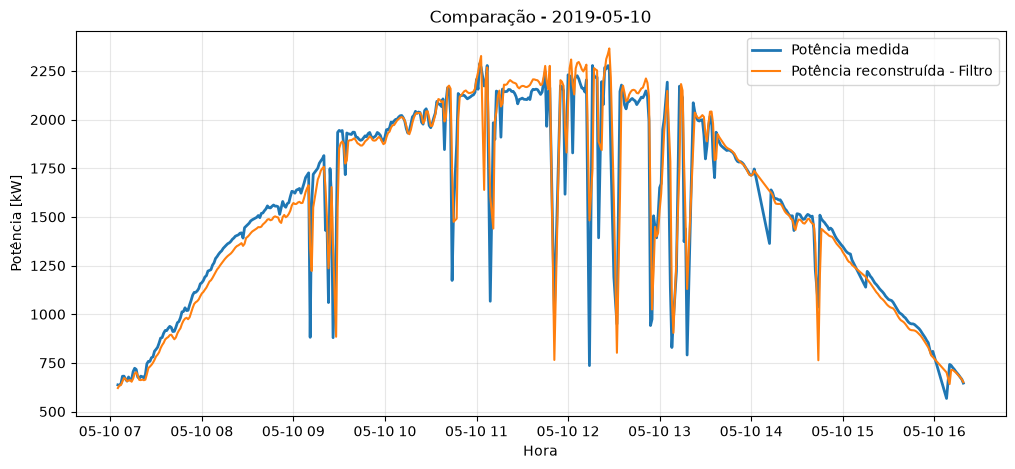

In [40]:
plotar_comparacao_dia("2019-05-10", comparacoes_dias)

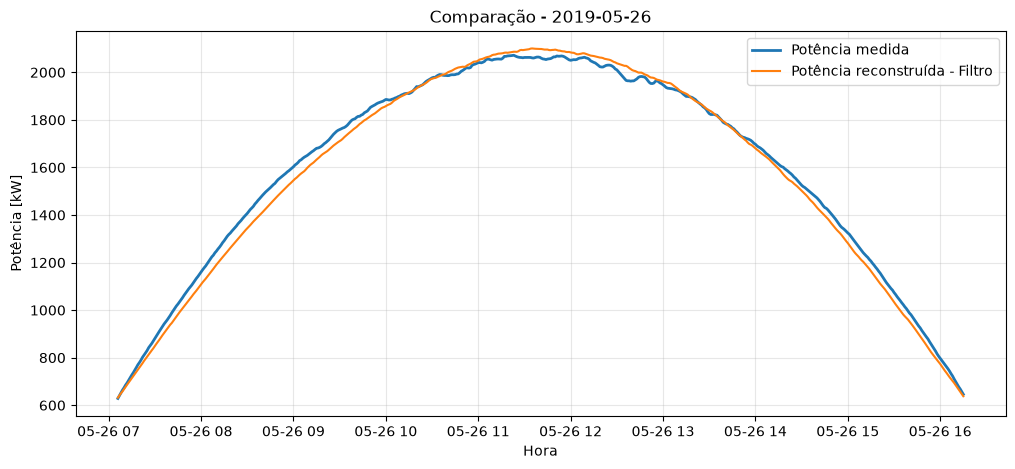

In [41]:
plotar_comparacao_dia("2019-05-26", comparacoes_dias)

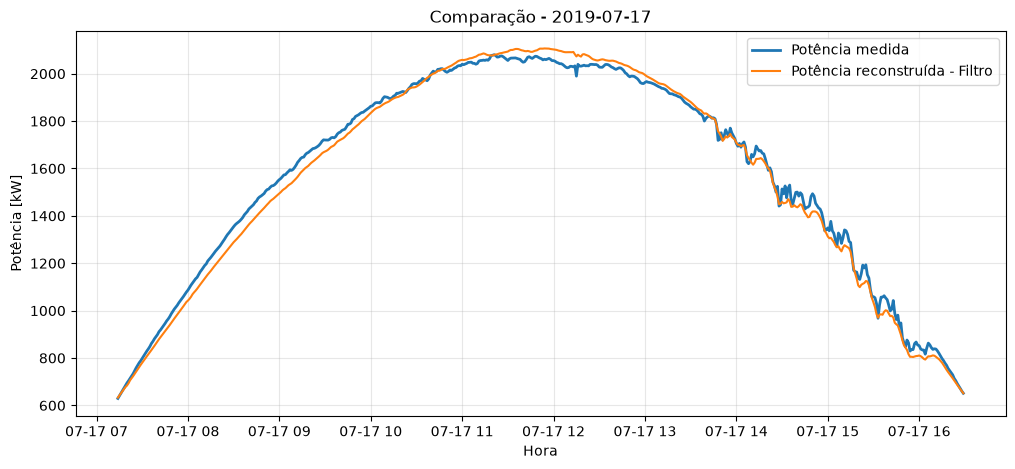

In [42]:
plotar_comparacao_dia("2019-07-17", comparacoes_dias)

In [43]:
data = "2019-07-19"

df_dia_1907 = df_full.loc[
    data,
    ["P", "G", "Zenith"]
].copy()

print(df_dia_1907.describe())

print("\nQuantidade de minutos com G >= 300:")
print((df_dia_1907["G"] >= 300).sum())

print("\nQuantidade de minutos com P > 0 e G >= 300:")
print(
    (
        (df_dia_1907["P"] > 0) &
        (df_dia_1907["G"] >= 300)
    ).sum()
)

                 P            G       Zenith
count  1379.000000  1379.000000  1440.000000
mean    208.858666    95.899756    95.162422
std     305.184583   136.736714    44.694923
min       0.000000     0.000000    30.211002
25%       0.000000     0.000000    53.573527
50%       0.000000     0.000000    93.326182
75%     366.350000   171.415000   135.207789
max    1609.700000   764.370000   168.670133

Quantidade de minutos com G >= 300:
161

Quantidade de minutos com P > 0 e G >= 300:
159


In [47]:
# ============================================================
# 15. DIAGNÓSTICO DA DISPONIBILIDADE DOS 21 DIAS
# ============================================================

diagnostico_dias = []

for data in DIAS_JOAO:

    data_str = data.strftime("%Y-%m-%d")

    df_dia = df_full.loc[
        data_str,
        ["P", "G", "Zenith"]
    ].copy()

    diagnostico_dias.append({
        "Data": data.date(),

        "N_total": len(df_dia),

        "NaN_P": df_dia["P"].isna().sum(),
        "NaN_G": df_dia["G"].isna().sum(),

        "G_max": df_dia["G"].max(),
        "G_media": df_dia["G"].mean(),

        "N_G>=300": (df_dia["G"] >= 300).sum(),

        "N_validos": (
            (df_dia["P"] > 0) &
            (df_dia["G"] >= 300)
        ).sum(),

        "P_max": df_dia["P"].max(),
        "P_media_G>=300": df_dia.loc[
            (df_dia["P"] > 0) &
            (df_dia["G"] >= 300),
            "P"
        ].mean()
    })

df_diagnostico = pd.DataFrame(diagnostico_dias).set_index("Data")

df_diagnostico.sort_values(
    "N_validos"
)

,N_total,NaN_P,NaN_G,G_max,G_media,N_G>=300,N_validos,P_max,P_media_G>=300
Data,,,,,,,,,
2019-07-19,1440,61,61,764.370000,95.899756,161,159,1609.7,860.644025
2019-04-24,1440,17,17,1047.677778,302.804174,489,464,2173.9,1748.074784
2019-05-10,1440,7,7,1129.290000,295.148488,540,498,2287.0,1588.945783
2019-08-02,1440,20,20,1278.500000,296.191284,523,506,2592.0,1613.658300
2019-05-24,1440,1,1,984.020000,291.689646,536,514,2033.8,1584.490661
2019-05-25,1440,6,6,992.350000,298.734778,547,524,2058.7,1599.646183
2019-09-15,1440,22,22,1061.480000,323.864227,542,527,2183.0,1698.832638
2019-07-16,1440,0,0,1003.060000,303.216209,553,530,2093.7,1616.036981
2019-09-19,1440,24,24,1132.760000,318.027164,548,531,2313.1,1637.280603


In [45]:
df_diagnostico["Fracao_valida_%"] = (
    100 *
    df_diagnostico["N_validos"] /
    df_diagnostico["N_total"]
)

df_diagnostico

,N_total,NaN_P,NaN_G,G_max,G_media,N_G>=300,N_validos,P_max,P_media_G>=300,Fracao_valida_%
Data,,,,,,,,,,
2019-03-16,1440,31,31,1090.480000,315.246480,551,541,2320.5,1618.024030,37.569444
2019-04-24,1440,17,17,1047.677778,302.804174,489,464,2173.9,1748.074784,32.222222
2019-05-04,1440,12,12,1055.900000,311.222560,544,532,2198.1,1665.452444,36.944444
2019-05-05,1440,13,13,1043.530000,312.541294,549,543,2162.5,1654.891897,37.708333
2019-05-06,1440,5,5,1053.270000,315.623275,557,548,2171.1,1652.112591,38.055556
2019-05-07,1440,18,18,1034.340000,310.193646,542,537,2135.4,1640.107449,37.291667
2019-05-10,1440,7,7,1129.290000,295.148488,540,498,2287.0,1588.945783,34.583333
2019-05-24,1440,1,1,984.020000,291.689646,536,514,2033.8,1584.490661,35.694444
2019-05-25,1440,6,6,992.350000,298.734778,547,524,2058.7,1599.646183,36.388889


In [46]:
# ============================================================
# 16. LOCALIZAÇÃO DAS LACUNAS DO DIA 19/07
# ============================================================

df_1907 = df_full.loc["2019-07-19"].copy()

mask_nan = (
    df_1907["P"].isna() |
    df_1907["G"].isna()
)

df_1907.loc[
    mask_nan,
    ["P", "G", "Zenith"]
]

,P,G,Zenith
Time,,,
2019-07-19 06:11:00,NaN,NaN,87.835403
2019-07-19 06:12:00,NaN,NaN,87.620186
2019-07-19 06:13:00,NaN,NaN,87.403832
2019-07-19 06:14:00,NaN,NaN,87.186470
2019-07-19 06:15:00,NaN,NaN,86.968214
...,...,...,...
2019-07-19 17:22:00,NaN,NaN,87.034154
2019-07-19 17:23:00,NaN,NaN,87.252235
2019-07-19 17:24:00,NaN,NaN,87.469389


In [48]:
# ============================================================
# 17. OTIMIZAÇÃO GLOBAL DO GANHO K NOS 21 DIAS
# ============================================================

from scipy.optimize import minimize_scalar


def calcular_rmse_consolidado_k(k, dias=DIAS_JOAO):

    comparacoes = []

    for data in dias:

        metricas, df_comp_dia = avaliar_dia_filtro(
            df=df_full,
            data=data,
            k=k,
            tau=tau,
            g_min=300
        )

        if df_comp_dia is not None:
            comparacoes.append(df_comp_dia)

    if len(comparacoes) == 0:
        return np.inf

    df_comp = pd.concat(comparacoes, axis=0)

    erro = (
        df_comp["P_Filtro"]
        - df_comp["P_Real"]
    )

    rmse = np.sqrt(
        np.mean(erro**2)
    )

    return rmse

In [49]:
rmse_k_global = calcular_rmse_consolidado_k(
    K_GLOBAL
)

print(
    f"RMSE com K = {K_GLOBAL:.3f}: "
    f"{rmse_k_global:.3f} kW"
)

RMSE com K = 2.106: 71.410 kW


In [50]:
resultado_otimizacao = minimize_scalar(
    calcular_rmse_consolidado_k,
    bounds=(1.5, 2.5),
    method="bounded",
    options={
        "xatol": 1e-6
    }
)

K_OTIMO_21 = resultado_otimizacao.x
RMSE_OTIMO_21 = resultado_otimizacao.fun

print(
    f"K global do artigo = {K_GLOBAL:.6f}"
)

print(
    f"K ótimo nos 21 dias = {K_OTIMO_21:.6f}"
)

print(
    f"RMSE mínimo = {RMSE_OTIMO_21:.3f} kW"
)

K global do artigo = 2.106000
K ótimo nos 21 dias = 2.110595
RMSE mínimo = 71.316 kW


In [51]:
# ============================================================
# 19. AVALIAÇÃO COM K OTIMIZADO NOS 21 DIAS
# ============================================================

resultados_k_otimo = []
comparacoes_k_otimo = []

for data in DIAS_JOAO:

    metricas, df_comp_dia = avaliar_dia_filtro(
        df=df_full,
        data=data,
        k=K_OTIMO_21,
        tau=tau,
        g_min=300
    )

    if metricas is not None:

        resultados_k_otimo.append(metricas)
        comparacoes_k_otimo.append(df_comp_dia)


df_metricas_k_otimo = pd.DataFrame(
    resultados_k_otimo
).set_index("Data")

In [52]:
df_comp_21_k_otimo = pd.concat(
    comparacoes_k_otimo,
    axis=0
)

metricas_filtro_21_k_otimo = calcular_metricas(
    df_comp_21_k_otimo["P_Real"],
    df_comp_21_k_otimo["P_Filtro"]
)

pd.Series(
    metricas_filtro_21_k_otimo
)

N             10711.000000
P_media_kW     1618.890104
RMSE_kW          71.316200
nRMSE_%           4.405253
nMAE_%            2.727292
nMBE_%           -0.496298
R2                0.975365
STDratio          1.049312
dtype: float64

In [53]:
comparacao_k_21 = pd.DataFrame({

    "K = 2.106 (artigo)":
        metricas_filtro_21,

    f"K = {K_OTIMO_21:.4f} (calibrado 21 dias)":
        metricas_filtro_21_k_otimo

}).T

comparacao_k_21

,N,P_media_kW,RMSE_kW,nRMSE_%,nMAE_%,nMBE_%,R2,STDratio
K = 2.106 (artigo),10711.0,1618.890104,71.409934,4.411043,2.735269,-0.712940,0.975300,1.047027
K = 2.1106 (calibrado 21 dias),10711.0,1618.890104,71.316200,4.405253,2.727292,-0.496298,0.975365,1.049312


In [54]:
# ============================================================
# 19. AVALIAÇÃO FINAL COM K OTIMIZADO NOS 21 DIAS
# ============================================================

resultados_k_otimo = []
comparacoes_k_otimo = []

for data in DIAS_JOAO:

    metricas, df_comp_dia = avaliar_dia_filtro(
        df=df_full,
        data=data,
        k=K_OTIMO_21,
        tau=tau,
        g_min=300
    )

    if metricas is not None:
        resultados_k_otimo.append(metricas)
        comparacoes_k_otimo.append(df_comp_dia)


df_metricas_k_otimo = pd.DataFrame(
    resultados_k_otimo
).set_index("Data")


# Consolidação de todos os pontos
df_comp_21_k_otimo = pd.concat(
    comparacoes_k_otimo,
    axis=0
)

metricas_filtro_21_k_otimo = calcular_metricas(
    df_comp_21_k_otimo["P_Real"],
    df_comp_21_k_otimo["P_Filtro"]
)

pd.Series(metricas_filtro_21_k_otimo)

N             10711.000000
P_media_kW     1618.890104
RMSE_kW          71.316200
nRMSE_%           4.405253
nMAE_%            2.727292
nMBE_%           -0.496298
R2                0.975365
STDratio          1.049312
dtype: float64

In [55]:
# ============================================================
# 20. COMPARAÇÃO K DO ARTIGO vs K OTIMIZADO
# ============================================================

comparacao_k_21 = pd.DataFrame({

    "K = 2.106 (artigo)":
        metricas_filtro_21,

    f"K = {K_OTIMO_21:.6f} (ótimo 21 dias)":
        metricas_filtro_21_k_otimo

}).T

comparacao_k_21

,N,P_media_kW,RMSE_kW,nRMSE_%,nMAE_%,nMBE_%,R2,STDratio
K = 2.106 (artigo),10711.0,1618.890104,71.409934,4.411043,2.735269,-0.712940,0.975300,1.047027
K = 2.110595 (ótimo 21 dias),10711.0,1618.890104,71.316200,4.405253,2.727292,-0.496298,0.975365,1.049312


In [56]:
# ============================================================
# 21. ANÁLISE DOS RESÍDUOS DO FILTRO
# ============================================================

df_erro = df_comp_21_k_otimo.copy()

df_erro["Erro_kW"] = (
    df_erro["P_Filtro"] -
    df_erro["P_Real"]
)

df_erro["Erro_abs_kW"] = df_erro["Erro_kW"].abs()

df_erro["Hora"] = df_erro.index.hour
df_erro["Minuto"] = df_erro.index.minute

df_erro["Hora_decimal"] = (
    df_erro["Hora"] +
    df_erro["Minuto"] / 60
)

df_erro.head()

,P_Real,P_Filtro,G,Data,Erro_kW,Erro_abs_kW,Hora,Minuto,Hora_decimal
Time,,,,,,,,,
2019-03-16 07:13:00,610.6,629.275235,300.97,2019-03-16,18.675235,18.675235,7,13,7.216667
2019-03-16 07:14:00,623.1,639.862748,305.68,2019-03-16,16.762748,16.762748,7,14,7.233333
2019-03-16 07:15:00,635.8,649.557406,310.13,2019-03-16,13.757406,13.757406,7,15,7.250000
2019-03-16 07:16:00,647.5,658.682568,314.31,2019-03-16,11.182568,11.182568,7,16,7.266667
2019-03-16 07:17:00,657.7,667.145804,318.13,2019-03-16,9.445804,9.445804,7,17,7.283333


In [57]:
erro_por_hora = (
    df_erro
    .groupby("Hora")
    .agg(
        N=("Erro_kW", "size"),
        Erro_medio_kW=("Erro_kW", "mean"),
        MAE_kW=("Erro_abs_kW", "mean"),
        P_real_media=("P_Real", "mean")
    )
)

erro_por_hora

,N,Erro_medio_kW,MAE_kW,P_real_media
Hora,,,,
6,16,-6.902822,37.603974,671.956250
7,988,-28.434201,39.745552,916.253543
8,1123,-54.628164,68.994075,1410.857614
9,1172,-37.463188,50.366295,1786.984044
10,1218,3.923491,28.158883,1979.742036
11,1197,40.643102,55.527243,2062.025898
12,1216,41.361032,56.280211,2006.157812
13,1202,16.307103,28.198326,1833.749418
14,1132,-25.003844,36.170664,1544.825000


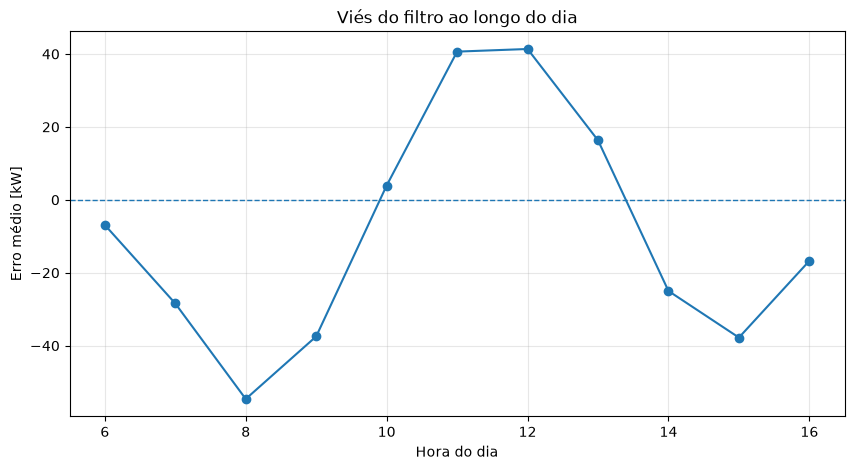

In [58]:
plt.figure(figsize=(10, 5))

plt.plot(
    erro_por_hora.index,
    erro_por_hora["Erro_medio_kW"],
    marker="o"
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.xlabel("Hora do dia")
plt.ylabel("Erro médio [kW]")
plt.title("Viés do filtro ao longo do dia")
plt.grid(alpha=0.3)

plt.show()

In [59]:
# ============================================================
# 22. ERRO EM FUNÇÃO DA IRRADIÂNCIA
# ============================================================

bins_G = np.arange(
    300,
    df_erro["G"].max() + 100,
    100
)

df_erro["Faixa_G"] = pd.cut(
    df_erro["G"],
    bins=bins_G,
    include_lowest=True
)

erro_por_G = (
    df_erro
    .groupby("Faixa_G", observed=True)
    .agg(
        N=("Erro_kW", "size"),
        G_media=("G", "mean"),
        Erro_medio_kW=("Erro_kW", "mean"),
        MAE_kW=("Erro_abs_kW", "mean")
    )
)

erro_por_G

,N,G_media,Erro_medio_kW,MAE_kW
Faixa_G,,,,
"(299.999, 400.0]",1011,348.669116,-7.740753,38.366126
"(400.0, 500.0]",940,450.025186,-26.628100,52.236837
"(500.0, 600.0]",900,551.221665,-46.132258,56.404361
"(600.0, 700.0]",1051,651.470131,-46.418618,64.225651
"(700.0, 800.0]",1195,749.724993,-33.714335,48.178339
"(800.0, 900.0]",1549,852.460930,-20.144886,34.851450
"(900.0, 1000.0]",2510,956.580408,17.666151,29.847765
"(1000.0, 1100.0]",1524,1031.861363,41.169631,50.867339
"(1100.0, 1200.0]",30,1122.496667,50.173067,91.674036


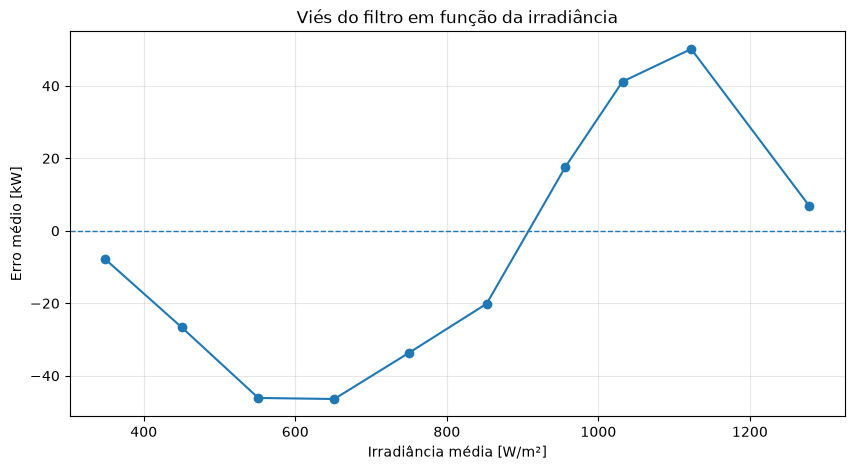

In [60]:
plt.figure(figsize=(10, 5))

plt.plot(
    erro_por_G["G_media"],
    erro_por_G["Erro_medio_kW"],
    marker="o"
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.xlabel("Irradiância média [W/m²]")
plt.ylabel("Erro médio [kW]")
plt.title("Viés do filtro em função da irradiância")
plt.grid(alpha=0.3)

plt.show()

In [61]:
# ============================================================
# 21. ANÁLISE DOS RESÍDUOS - K = 2.106
# ============================================================

df_erro = df_comp_21.copy()

# Resíduo: estimado - medido
df_erro["Erro_kW"] = (
    df_erro["P_Filtro"] -
    df_erro["P_Real"]
)

df_erro["Erro_abs_kW"] = df_erro["Erro_kW"].abs()

# Hora decimal
df_erro["Hora"] = df_erro.index.hour
df_erro["Minuto"] = df_erro.index.minute

df_erro["Hora_decimal"] = (
    df_erro["Hora"] +
    df_erro["Minuto"] / 60
)

df_erro.head()

,P_Real,P_Filtro,G,Data,Erro_kW,Erro_abs_kW,Hora,Minuto,Hora_decimal
Time,,,,,,,,,
2019-03-16 07:13:00,610.6,627.944937,300.97,2019-03-16,17.344937,17.344937,7,13,7.216667
2019-03-16 07:14:00,623.1,638.470811,305.68,2019-03-16,15.370811,15.370811,7,14,7.233333
2019-03-16 07:15:00,635.8,648.143182,310.13,2019-03-16,12.343182,12.343182,7,15,7.250000
2019-03-16 07:16:00,647.5,657.248440,314.31,2019-03-16,9.748440,9.748440,7,16,7.266667
2019-03-16 07:17:00,657.7,665.693249,318.13,2019-03-16,7.993249,7.993249,7,17,7.283333


In [62]:
# ============================================================
# 22. ERRO MÉDIO POR HORA DO DIA
# ============================================================

erro_por_hora = (
    df_erro
    .groupby("Hora")
    .agg(
        N=("Erro_kW", "size"),
        Erro_medio_kW=("Erro_kW", "mean"),
        MAE_kW=("Erro_abs_kW", "mean"),
        P_real_media_kW=("P_Real", "mean")
    )
)

erro_por_hora

,N,Erro_medio_kW,MAE_kW,P_real_media_kW
Hora,,,,
6,16,-8.342398,37.222952,671.956250
7,988,-30.366539,41.191247,916.253543
8,1123,-57.581039,71.645580,1410.857614
9,1172,-41.272329,53.744943,1786.984044
10,1218,-0.395481,27.864226,1979.742036
11,1197,36.065028,51.390416,2062.025898
12,1216,36.903035,52.210721,2006.157812
13,1202,12.279034,25.937096,1833.749418
14,1132,-28.312902,38.972468,1544.825000


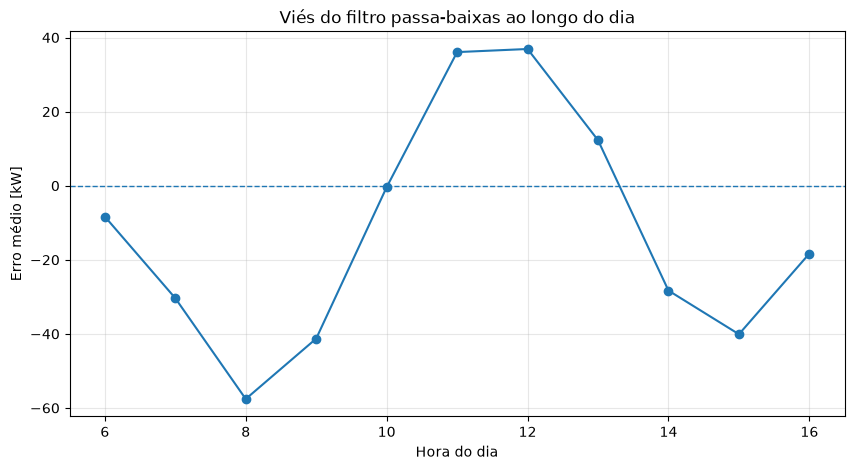

In [63]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    erro_por_hora.index,
    erro_por_hora["Erro_medio_kW"],
    marker="o"
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.xlabel("Hora do dia")
plt.ylabel("Erro médio [kW]")
plt.title("Viés do filtro passa-baixas ao longo do dia")
plt.grid(alpha=0.3)

plt.show()

In [64]:
# ============================================================
# 23. ERRO EM FUNÇÃO DA IRRADIÂNCIA
# ============================================================

bins_G = np.arange(
    300,
    df_erro["G"].max() + 100,
    100
)

df_erro["Faixa_G"] = pd.cut(
    df_erro["G"],
    bins=bins_G,
    include_lowest=True
)

erro_por_G = (
    df_erro
    .groupby("Faixa_G", observed=True)
    .agg(
        N=("Erro_kW", "size"),
        G_media=("G", "mean"),
        Erro_medio_kW=("Erro_kW", "mean"),
        MAE_kW=("Erro_abs_kW", "mean")
    )
)

erro_por_G

,N,G_media,Erro_medio_kW,MAE_kW
Faixa_G,,,,
"(299.999, 400.0]",1011,348.669116,-9.361344,39.252387
"(400.0, 500.0]",940,450.025186,-28.707914,53.896138
"(500.0, 600.0]",900,551.221665,-48.659283,58.681501
"(600.0, 700.0]",1051,651.470131,-49.403799,66.866044
"(700.0, 800.0]",1195,749.724993,-37.161154,51.244935
"(800.0, 900.0]",1549,852.460930,-24.053447,36.477866
"(900.0, 1000.0]",2510,956.580408,13.274781,27.727938
"(1000.0, 1100.0]",1524,1031.861363,36.441041,46.496703
"(1100.0, 1200.0]",30,1122.496667,45.086658,88.551927


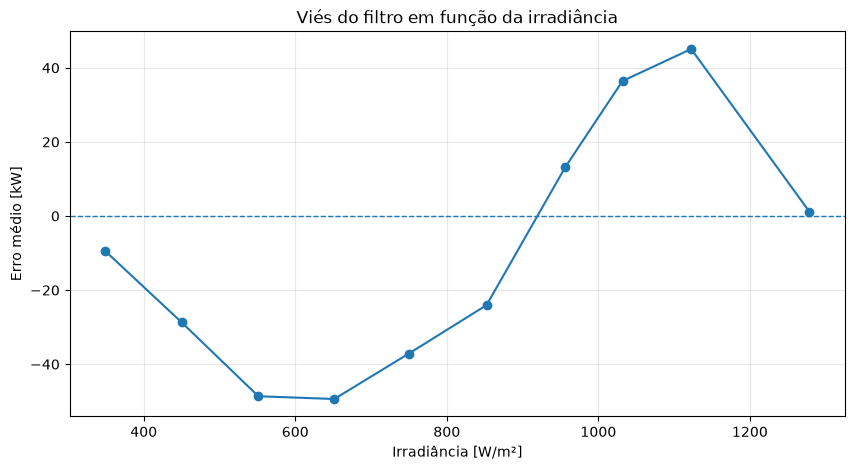

In [65]:
plt.figure(figsize=(10, 5))

plt.plot(
    erro_por_G["G_media"],
    erro_por_G["Erro_medio_kW"],
    marker="o"
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.xlabel("Irradiância [W/m²]")
plt.ylabel("Erro médio [kW]")
plt.title("Viés do filtro em função da irradiância")
plt.grid(alpha=0.3)

plt.show()

In [66]:
# ============================================================
# 24. GANHO EFETIVO OBSERVADO NOS DADOS
# ============================================================

df_erro["K_efetivo"] = (
    df_erro["P_Real"] /
    df_erro["G"]
)

df_erro["K_efetivo"].describe()

count    10711.000000
mean         2.130712
std          0.059893
min          1.535950
25%          2.084440
50%          2.131252
75%          2.177145
max          2.461253
Name: K_efetivo, dtype: float64

In [67]:
# ============================================================
# 25. K EFETIVO EM FUNÇÃO DA HORA
# ============================================================

k_por_hora = (
    df_erro
    .groupby("Hora")
    .agg(
        N=("K_efetivo", "size"),
        K_medio=("K_efetivo", "mean"),
        K_mediano=("K_efetivo", "median"),
        K_std=("K_efetivo", "std")
    )
)

k_por_hora

,N,K_medio,K_mediano,K_std
Hora,,,,
6,16,2.055252,2.055815,0.044197
7,988,2.154774,2.164708,0.054037
8,1123,2.186114,2.194204,0.040777
9,1172,2.153414,2.157316,0.033301
10,1218,2.105526,2.105813,0.040809
11,1197,2.072540,2.069384,0.044807
12,1216,2.071515,2.067398,0.045773
13,1202,2.098599,2.096289,0.037954
14,1132,2.147973,2.147964,0.038942


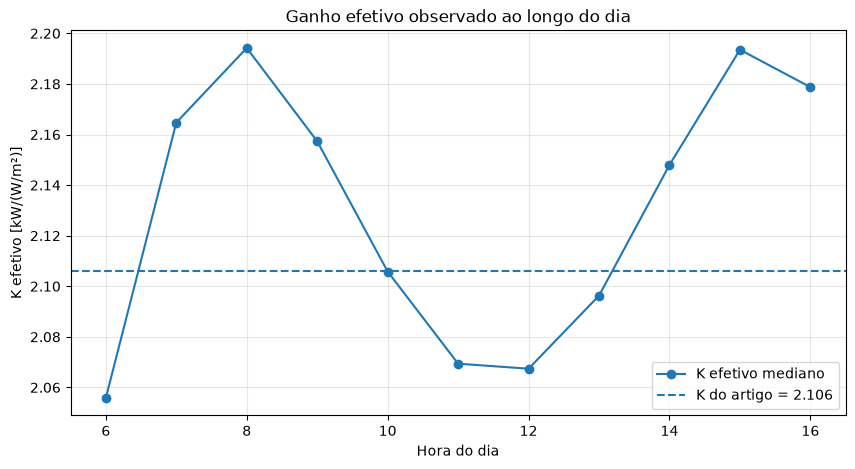

In [68]:
plt.figure(figsize=(10, 5))

plt.plot(
    k_por_hora.index,
    k_por_hora["K_mediano"],
    marker="o",
    label="K efetivo mediano"
)

plt.axhline(
    2.106,
    linestyle="--",
    label="K do artigo = 2.106"
)

plt.xlabel("Hora do dia")
plt.ylabel("K efetivo [kW/(W/m²)]")
plt.title("Ganho efetivo observado ao longo do dia")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [69]:
# ============================================================
# 26. K EFETIVO EM FUNÇÃO DA IRRADIÂNCIA
# ============================================================

k_por_G = (
    df_erro
    .groupby("Faixa_G", observed=True)
    .agg(
        N=("K_efetivo", "size"),
        G_media=("G", "mean"),
        K_medio=("K_efetivo", "mean"),
        K_mediano=("K_efetivo", "median"),
        K_std=("K_efetivo", "std")
    )
)

k_por_G

,N,G_media,K_medio,K_mediano,K_std
Faixa_G,,,,,
"(299.999, 400.0]",1011,348.669116,2.156323,2.156967,0.070683
"(400.0, 500.0]",940,450.025186,2.182007,2.188902,0.058073
"(500.0, 600.0]",900,551.221665,2.189395,2.195021,0.037588
"(600.0, 700.0]",1051,651.470131,2.176067,2.182716,0.044397
"(700.0, 800.0]",1195,749.724993,2.156838,2.161807,0.044872
"(800.0, 900.0]",1549,852.460930,2.129831,2.131176,0.034941
"(900.0, 1000.0]",2510,956.580408,2.090336,2.089785,0.026493
"(1000.0, 1100.0]",1524,1031.861363,2.064983,2.065340,0.020048
"(1100.0, 1200.0]",30,1122.496667,2.036284,2.039832,0.032350


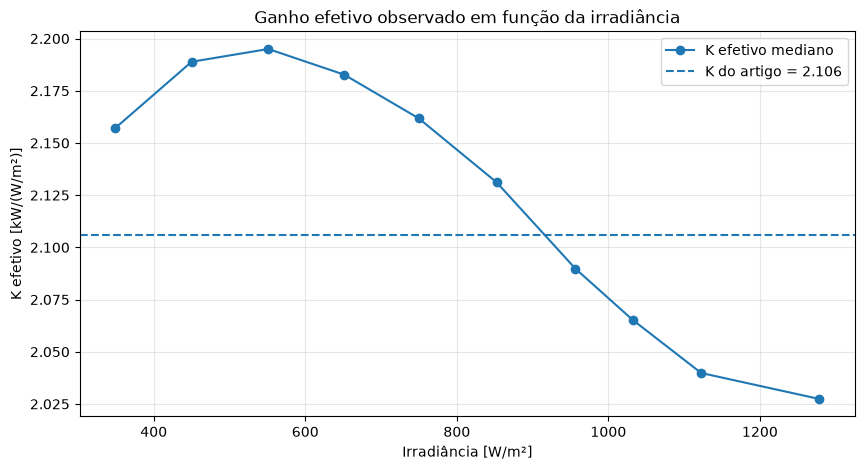

In [70]:
plt.figure(figsize=(10, 5))

plt.plot(
    k_por_G["G_media"],
    k_por_G["K_mediano"],
    marker="o",
    label="K efetivo mediano"
)

plt.axhline(
    2.106,
    linestyle="--",
    label="K do artigo = 2.106"
)

plt.xlabel("Irradiância [W/m²]")
plt.ylabel("K efetivo [kW/(W/m²)]")
plt.title("Ganho efetivo observado em função da irradiância")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [76]:
# ============================================================
# 27. ANÁLISE 2D DO GANHO EFETIVO: HORA x IRRADIÂNCIA
# ============================================================

bins_G = np.arange(
    300,
    df_erro["G"].max() + 100,
    100
)

df_erro["Faixa_G_2D"] = pd.cut(
    df_erro["G"],
    bins=bins_G,
    include_lowest=True
)

k_2d = (
    df_erro
    .groupby(
        ["Hora", "Faixa_G_2D"],
        observed=True
    )
    .agg(
        N=("K_efetivo", "size"),
        K_mediano=("K_efetivo", "median"),
        K_medio=("K_efetivo", "mean")
    )
    .reset_index()
)

k_2d.head()

,Hora,Faixa_G_2D,N,K_mediano,K_medio
0,6,"(299.999, 400.0]",16,2.055815,2.055252
1,7,"(299.999, 400.0]",413,2.128306,2.122793
2,7,"(400.0, 500.0]",393,2.178754,2.173259
3,7,"(500.0, 600.0]",159,2.196114,2.187724
4,7,"(600.0, 700.0]",20,2.196791,2.182340


In [77]:
matriz_k = k_2d.pivot(
    index="Hora",
    columns="Faixa_G_2D",
    values="K_mediano"
)

matriz_n = k_2d.pivot(
    index="Hora",
    columns="Faixa_G_2D",
    values="N"
)

display(matriz_k)
display(matriz_n)

Faixa_G_2D,"(299.999, 400.0]","(400.0, 500.0]","(500.0, 600.0]","(600.0, 700.0]","(700.0, 800.0]","(800.0, 900.0]","(900.0, 1000.0]","(1000.0, 1100.0]","(1100.0, 1200.0]","(1200.0, 1300.0]"
Hora,,,,,,,,,,
6,2.055815,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2.128306,2.178754,2.196114,2.196791,2.204806,NaN,NaN,NaN,NaN,NaN
8,2.151917,2.121149,2.200332,2.198719,2.185387,2.161462,NaN,NaN,NaN,NaN
9,2.197570,2.097294,2.169009,2.158808,2.177019,2.155060,2.129695,NaN,NaN,NaN
10,2.234846,2.200398,2.266598,2.091757,2.058298,2.127794,2.108242,2.081931,1.981862,NaN
11,2.247478,2.215445,2.208149,1.953716,2.099293,2.118789,2.078626,2.064835,2.054488,2.027376
12,2.261158,2.241965,1.898436,2.116822,2.053998,2.099094,2.074735,2.059021,2.030355,NaN
13,2.248946,2.221287,2.217814,1.977439,2.129744,2.105920,2.084176,2.049240,NaN,NaN
14,2.242349,2.249843,2.175722,2.165810,2.143296,2.122882,NaN,NaN,NaN,NaN


Faixa_G_2D,"(299.999, 400.0]","(400.0, 500.0]","(500.0, 600.0]","(600.0, 700.0]","(700.0, 800.0]","(800.0, 900.0]","(900.0, 1000.0]","(1000.0, 1100.0]","(1100.0, 1200.0]","(1200.0, 1300.0]"
Hora,,,,,,,,,,
6,16.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,413.0,393.0,159.0,20.0,3.0,NaN,NaN,NaN,NaN,NaN
8,18.0,32.0,278.0,474.0,296.0,25.0,NaN,NaN,NaN,NaN
9,6.0,8.0,6.0,11.0,296.0,677.0,168.0,NaN,NaN,NaN
10,19.0,13.0,6.0,7.0,9.0,100.0,806.0,257.0,1.0,NaN
11,29.0,10.0,3.0,3.0,6.0,8.0,350.0,768.0,19.0,1.0
12,35.0,11.0,1.0,9.0,7.0,12.0,640.0,491.0,10.0,NaN
13,28.0,13.0,4.0,6.0,27.0,570.0,546.0,8.0,NaN,NaN
14,11.0,9.0,13.0,391.0,551.0,157.0,NaN,NaN,NaN,NaN


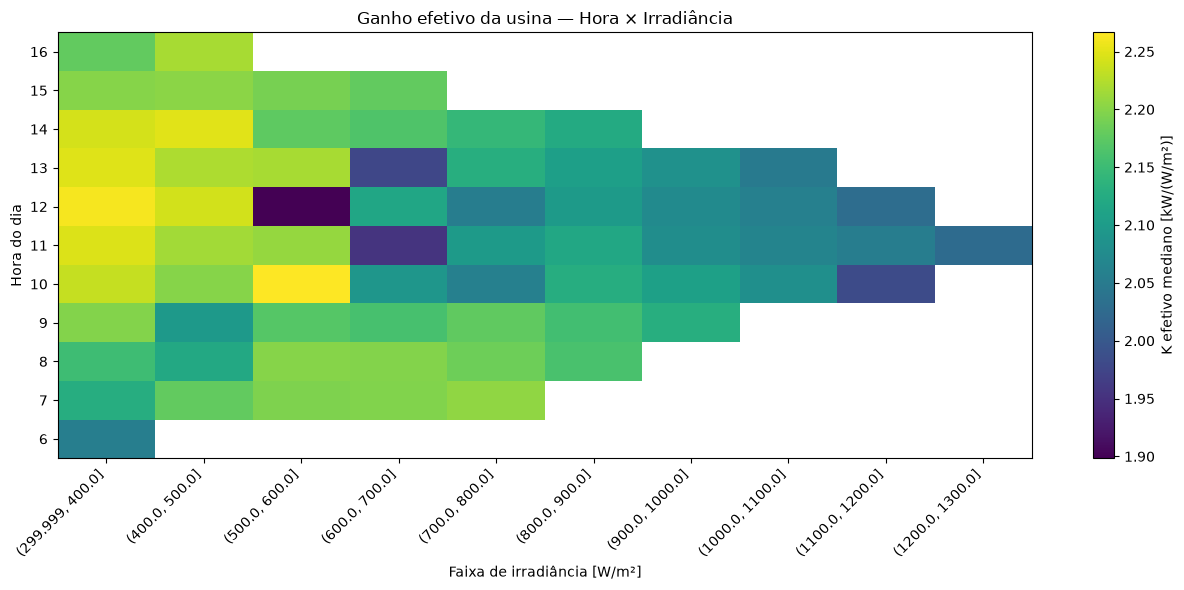

In [78]:
plt.figure(figsize=(13, 6))

plt.imshow(
    matriz_k,
    aspect="auto",
    origin="lower"
)

plt.colorbar(
    label="K efetivo mediano [kW/(W/m²)]"
)

plt.xticks(
    range(len(matriz_k.columns)),
    [str(x) for x in matriz_k.columns],
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(matriz_k.index)),
    matriz_k.index
)

plt.xlabel("Faixa de irradiância [W/m²]")
plt.ylabel("Hora do dia")

plt.title(
    "Ganho efetivo da usina — Hora × Irradiância"
)

plt.tight_layout()
plt.show()

In [79]:
df_erro.groupby("Hora").agg(
    N=("K_efetivo", "size"),
    G_media=("G", "mean"),
    K_mediano=("K_efetivo", "median")
)

,N,G_media,K_mediano
Hora,,,
6,16,326.696250,2.055815
7,988,424.124184,2.164708
8,1123,645.233000,2.194204
9,1172,830.154106,2.157316
10,1218,941.231084,2.105813
11,1197,996.394261,2.069384
12,1216,970.271870,2.067398
13,1202,875.197097,2.096289
14,1132,719.817503,2.147964


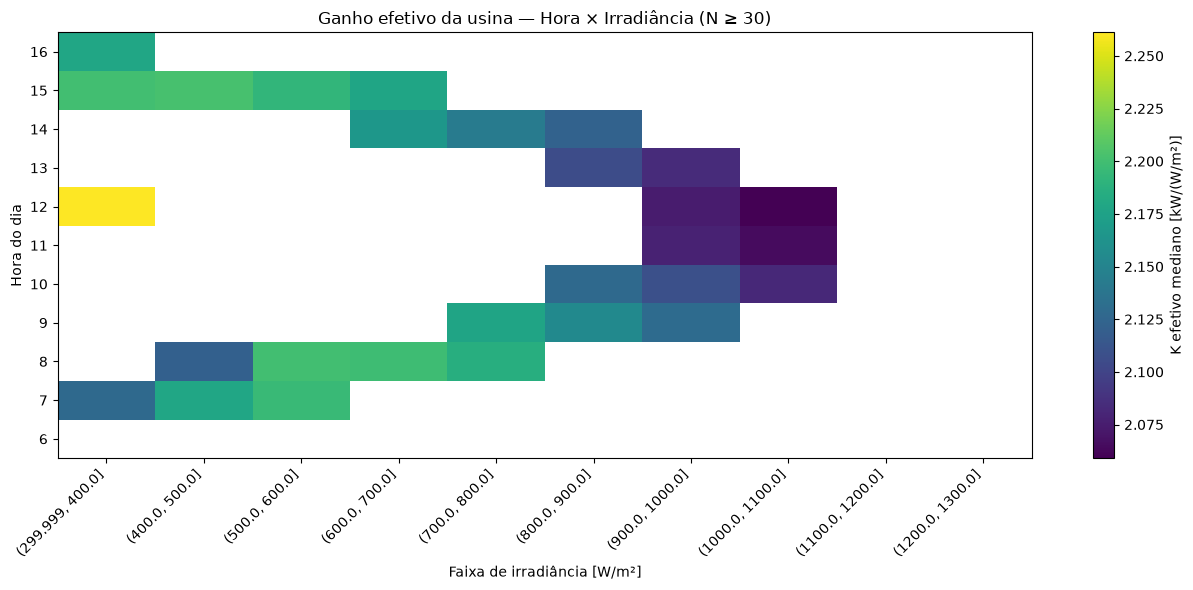

In [80]:
# ============================================================
# 28. MAPA 2D COM SUPORTE MÍNIMO DE OBSERVAÇÕES
# ============================================================

N_MIN = 30

matriz_k_filtrada = matriz_k.copy()

# Remove células com poucas observações
matriz_k_filtrada[matriz_n < N_MIN] = np.nan

plt.figure(figsize=(13, 6))

imagem = plt.imshow(
    matriz_k_filtrada,
    aspect="auto",
    origin="lower"
)

plt.colorbar(
    imagem,
    label="K efetivo mediano [kW/(W/m²)]"
)

plt.xticks(
    range(len(matriz_k_filtrada.columns)),
    [str(x) for x in matriz_k_filtrada.columns],
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(matriz_k_filtrada.index)),
    matriz_k_filtrada.index
)

plt.xlabel("Faixa de irradiância [W/m²]")
plt.ylabel("Hora do dia")

plt.title(
    f"Ganho efetivo da usina — Hora × Irradiância (N ≥ {N_MIN})"
)

plt.tight_layout()
plt.show()

In [81]:
display(matriz_n)

Faixa_G_2D,"(299.999, 400.0]","(400.0, 500.0]","(500.0, 600.0]","(600.0, 700.0]","(700.0, 800.0]","(800.0, 900.0]","(900.0, 1000.0]","(1000.0, 1100.0]","(1100.0, 1200.0]","(1200.0, 1300.0]"
Hora,,,,,,,,,,
6,16.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,413.0,393.0,159.0,20.0,3.0,NaN,NaN,NaN,NaN,NaN
8,18.0,32.0,278.0,474.0,296.0,25.0,NaN,NaN,NaN,NaN
9,6.0,8.0,6.0,11.0,296.0,677.0,168.0,NaN,NaN,NaN
10,19.0,13.0,6.0,7.0,9.0,100.0,806.0,257.0,1.0,NaN
11,29.0,10.0,3.0,3.0,6.0,8.0,350.0,768.0,19.0,1.0
12,35.0,11.0,1.0,9.0,7.0,12.0,640.0,491.0,10.0,NaN
13,28.0,13.0,4.0,6.0,27.0,570.0,546.0,8.0,NaN,NaN
14,11.0,9.0,13.0,391.0,551.0,157.0,NaN,NaN,NaN,NaN


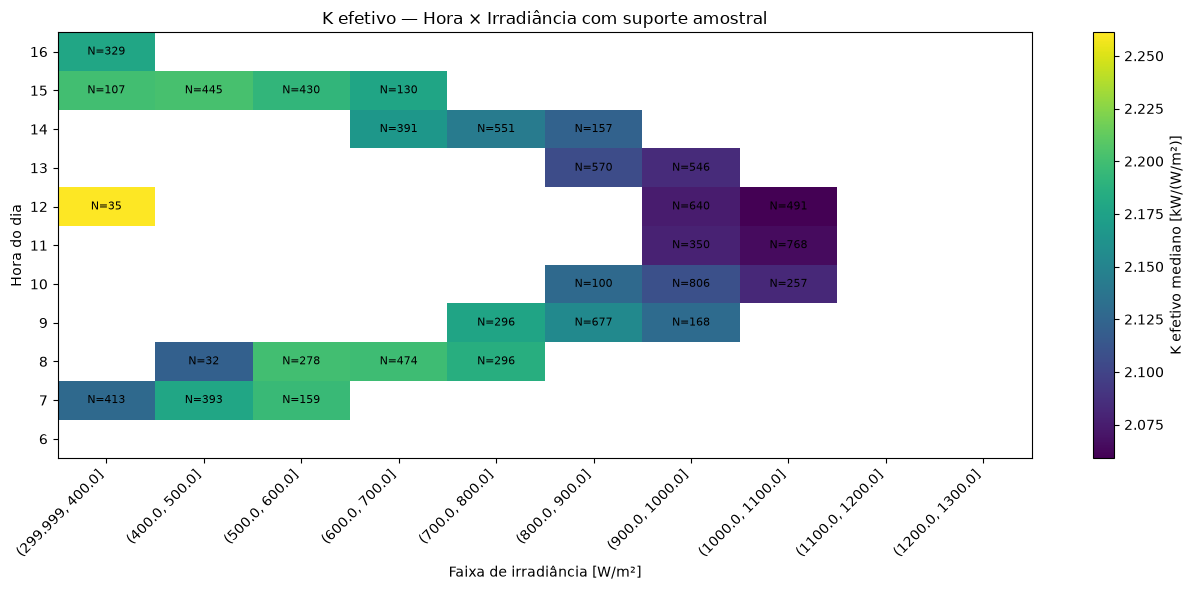

In [82]:
plt.figure(figsize=(13, 6))

imagem = plt.imshow(
    matriz_k_filtrada,
    aspect="auto",
    origin="lower"
)

plt.colorbar(
    imagem,
    label="K efetivo mediano [kW/(W/m²)]"
)

for i in range(matriz_n.shape[0]):
    for j in range(matriz_n.shape[1]):

        n = matriz_n.iloc[i, j]

        if pd.notna(n) and n >= N_MIN:
            plt.text(
                j,
                i,
                f"N={int(n)}",
                ha="center",
                va="center",
                fontsize=8
            )

plt.xticks(
    range(len(matriz_k_filtrada.columns)),
    [str(x) for x in matriz_k_filtrada.columns],
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(matriz_k_filtrada.index)),
    matriz_k_filtrada.index
)

plt.xlabel("Faixa de irradiância [W/m²]")
plt.ylabel("Hora do dia")
plt.title("K efetivo — Hora × Irradiância com suporte amostral")

plt.tight_layout()
plt.show()

In [83]:
# ============================================================
# 29. DIAS FORA DO CONJUNTO DE CALIBRAÇÃO DO JOÃO
# ============================================================

todos_dias = pd.date_range(
    "2019-01-01",
    "2019-12-31",
    freq="D"
)

dias_joao_normalizados = pd.DatetimeIndex(
    DIAS_JOAO
).normalize()

DIAS_TESTE = todos_dias[
    ~todos_dias.isin(dias_joao_normalizados)
]

print("Dias totais em 2019:", len(todos_dias))
print("Dias de calibração:", len(DIAS_JOAO))
print("Dias restantes:", len(DIAS_TESTE))

Dias totais em 2019: 365
Dias de calibração: 21
Dias restantes: 344


In [84]:
# ============================================================
# 30. SELEÇÃO DE DIAS COM SUPORTE MÍNIMO
# ============================================================

dias_teste_validos = []

for data in DIAS_TESTE:

    df_dia = df_full.loc[
        data.strftime("%Y-%m-%d")
    ]

    n_validos = (
        (df_dia["P"] > 0) &
        (df_dia["G"] >= 300)
    ).sum()

    if n_validos >= 400:
        dias_teste_validos.append(data)

print("Dias disponíveis para teste:", len(dias_teste_validos))

Dias disponíveis para teste: 198


In [85]:
# ============================================================
# 31. AVALIAÇÃO DO FILTRO NOS 198 DIAS DE TESTE
# ============================================================

resultados_teste = []
comparacoes_teste = []

for data in dias_teste_validos:

    metricas, df_comp_dia = avaliar_dia_filtro(
        df=df_full,
        data=data,
        k=K_GLOBAL,      # K = 2.106
        tau=tau,
        g_min=300
    )

    if metricas is not None:

        resultados_teste.append(metricas)
        comparacoes_teste.append(df_comp_dia)


df_metricas_teste = pd.DataFrame(
    resultados_teste
).set_index("Data")

print("Dias efetivamente avaliados:", len(df_metricas_teste))

df_metricas_teste.head()

Dias efetivamente avaliados: 198


,N,P_media_kW,RMSE_kW,nRMSE_%,nMAE_%,nMBE_%,R2,STDratio
Data,,,,,,,,
2019-01-01,484,1451.367355,190.084507,13.096926,7.244673,-1.672880,0.859270,0.969920
2019-01-03,454,1605.364978,123.936993,7.720175,4.255497,-2.558659,0.897865,1.031628
2019-01-05,424,1279.434906,134.753070,10.532233,7.489686,-3.416916,0.902265,0.982367
2019-01-08,468,1052.825427,103.162289,9.798613,7.932791,-6.098404,0.914923,0.999504
2019-01-09,426,1392.853521,181.921703,13.061079,9.348040,-2.897677,0.869578,0.983642


In [86]:
# ============================================================
# 32. MÉTRICAS CONSOLIDADAS - CONJUNTO DE TESTE
# ============================================================

df_comp_teste = pd.concat(
    comparacoes_teste,
    axis=0
)

metricas_filtro_teste = calcular_metricas(
    df_comp_teste["P_Real"],
    df_comp_teste["P_Filtro"]
)

pd.Series(metricas_filtro_teste)

N             92215.000000
P_media_kW     1501.974610
RMSE_kW         152.389255
nRMSE_%          10.145928
nMAE_%            5.862740
nMBE_%           -0.045733
R2                0.900589
STDratio          1.030836
dtype: float64

In [87]:
# ============================================================
# 33. CALIBRAÇÃO vs GENERALIZAÇÃO DO FILTRO
# ============================================================

comparacao_generalizacao = pd.DataFrame({

    "21 dias do João":
        metricas_filtro_21,

    "198 dias fora dos 21":
        metricas_filtro_teste

}).T

comparacao_generalizacao

,N,P_media_kW,RMSE_kW,nRMSE_%,nMAE_%,nMBE_%,R2,STDratio
21 dias do João,10711.0,1618.890104,71.409934,4.411043,2.735269,-0.712940,0.975300,1.047027
198 dias fora dos 21,92215.0,1501.974610,152.389255,10.145928,5.862740,-0.045733,0.900589,1.030836


In [88]:
nrmse_21 = metricas_filtro_21["nRMSE_%"]
nrmse_teste = metricas_filtro_teste["nRMSE_%"]

delta_nrmse = nrmse_teste - nrmse_21

aumento_relativo = (
    100 * delta_nrmse / nrmse_21
)

print(f"nRMSE nos 21 dias:  {nrmse_21:.3f}%")
print(f"nRMSE nos 198 dias: {nrmse_teste:.3f}%")
print(f"Variação absoluta:  {delta_nrmse:+.3f} p.p.")
print(f"Variação relativa:  {aumento_relativo:+.2f}%")

nRMSE nos 21 dias:  4.411%
nRMSE nos 198 dias: 10.146%
Variação absoluta:  +5.735 p.p.
Variação relativa:  +130.01%


In [89]:
nrmse_21 = metricas_filtro_21["nRMSE_%"]
nrmse_teste = metricas_filtro_teste["nRMSE_%"]

delta_nrmse = nrmse_teste - nrmse_21

aumento_relativo = (
    100 * delta_nrmse / nrmse_21
)

print(f"nRMSE nos 21 dias:  {nrmse_21:.3f}%")
print(f"nRMSE nos 198 dias: {nrmse_teste:.3f}%")
print(f"Variação absoluta:  {delta_nrmse:+.3f} p.p.")
print(f"Variação relativa:  {aumento_relativo:+.2f}%")

nRMSE nos 21 dias:  4.411%
nRMSE nos 198 dias: 10.146%
Variação absoluta:  +5.735 p.p.
Variação relativa:  +130.01%


In [90]:
print(
    "Mediana do nRMSE diário:",
    df_metricas_teste["nRMSE_%"].median()
)

print(
    "P90 do nRMSE diário:",
    df_metricas_teste["nRMSE_%"].quantile(0.90)
)

print(
    "P95 do nRMSE diário:",
    df_metricas_teste["nRMSE_%"].quantile(0.95)
)

Mediana do nRMSE diário: 9.72774364258362
P90 do nRMSE diário: 16.001849982994603
P95 do nRMSE diário: 17.319997416287464


In [91]:
# ============================================================
# 36. DISTRIBUIÇÃO DO DESEMPENHO NOS 198 DIAS
# ============================================================

resumo_nrmse = df_metricas_teste["nRMSE_%"].describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
)

resumo_nrmse

count    198.000000
mean       9.640827
std        4.518316
min        1.747223
10%        3.507103
25%        6.012132
50%        9.727744
75%       12.700912
90%       16.001850
95%       17.319997
max       22.582183
Name: nRMSE_%, dtype: float64

In [92]:
print(
    "Dias com nRMSE < 5%:",
    (df_metricas_teste["nRMSE_%"] < 5).sum()
)

print(
    "Dias com nRMSE < 10%:",
    (df_metricas_teste["nRMSE_%"] < 10).sum()
)

print(
    "Dias com nRMSE >= 10%:",
    (df_metricas_teste["nRMSE_%"] >= 10).sum()
)

Dias com nRMSE < 5%: 39
Dias com nRMSE < 10%: 104
Dias com nRMSE >= 10%: 94


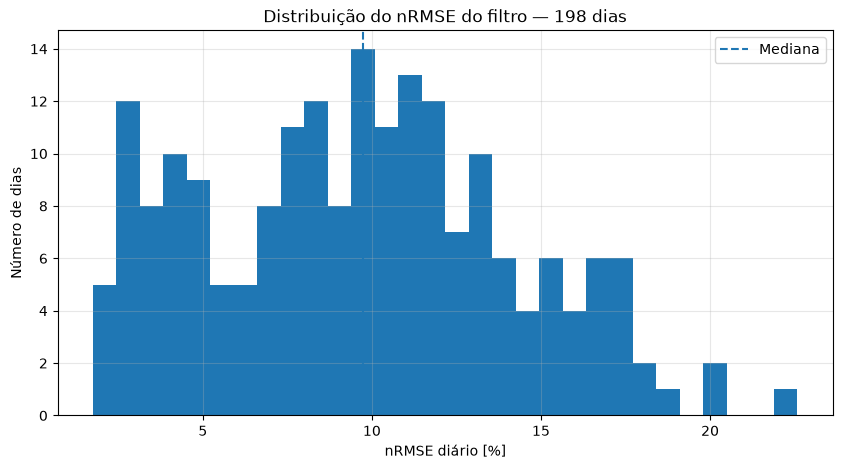

In [93]:
plt.figure(figsize=(10, 5))

plt.hist(
    df_metricas_teste["nRMSE_%"],
    bins=30
)

plt.axvline(
    df_metricas_teste["nRMSE_%"].median(),
    linestyle="--",
    label="Mediana"
)

plt.xlabel("nRMSE diário [%]")
plt.ylabel("Número de dias")
plt.title("Distribuição do nRMSE do filtro — 198 dias")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [94]:
# ============================================================
# 37. ÍNDICE SIMPLES DE VARIABILIDADE DA IRRADIÂNCIA
# ============================================================

variabilidade_dias = []

for data in dias_teste_validos:

    data_str = data.strftime("%Y-%m-%d")

    df_dia = df_full.loc[data_str].copy()

    mask = (
        df_dia["G"].notna() &
        (df_dia["G"] >= 300)
    )

    G = df_dia.loc[mask, "G"]

    if len(G) < 2:
        continue

    VI_G = G.diff().abs().mean()

    variabilidade_dias.append({
        "Data": data.date(),
        "VI_G": VI_G
    })

df_variabilidade = (
    pd.DataFrame(variabilidade_dias)
    .set_index("Data")
)

df_analise_variabilidade = (
    df_metricas_teste
    .join(df_variabilidade)
)

df_analise_variabilidade[
    ["nRMSE_%", "VI_G"]
].head()

,nRMSE_%,VI_G
Data,,
2019-01-01,13.096926,71.242179
2019-01-03,7.720175,30.891189
2019-01-05,10.532233,64.659743
2019-01-08,9.798613,33.093404
2019-01-09,13.061079,93.582727


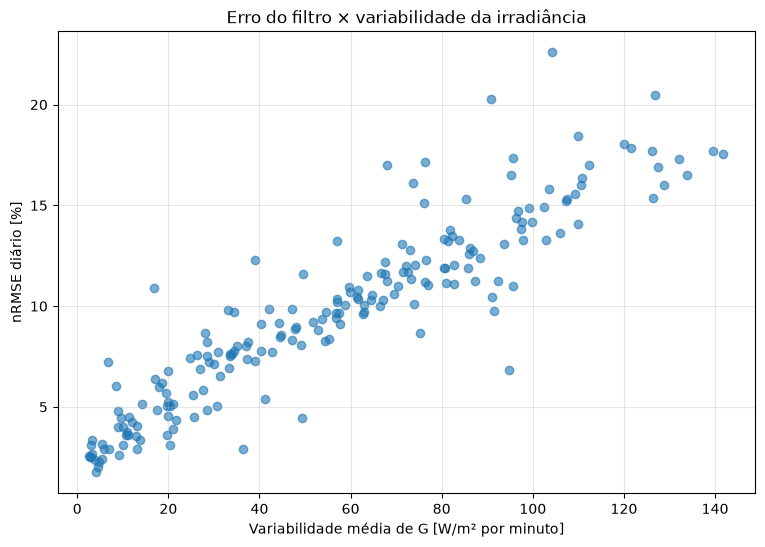

In [95]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df_analise_variabilidade["VI_G"],
    df_analise_variabilidade["nRMSE_%"],
    alpha=0.6
)

plt.xlabel("Variabilidade média de G [W/m² por minuto]")
plt.ylabel("nRMSE diário [%]")
plt.title("Erro do filtro × variabilidade da irradiância")
plt.grid(alpha=0.3)

plt.show()

In [96]:
correlacao = (
    df_analise_variabilidade[
        ["VI_G", "nRMSE_%"]
    ]
    .corr()
)

correlacao

,VI_G,nRMSE_%
VI_G,1.00000,0.91668
nRMSE_%,0.91668,1.00000


In [97]:
# ============================================================
# 38. CORRELAÇÃO: VARIABILIDADE x ERRO
# ============================================================

corr_pearson = df_analise_variabilidade[
    ["VI_G", "nRMSE_%"]
].corr(method="pearson").loc["VI_G", "nRMSE_%"]

corr_spearman = df_analise_variabilidade[
    ["VI_G", "nRMSE_%"]
].corr(method="spearman").loc["VI_G", "nRMSE_%"]

print(f"Correlação de Pearson : {corr_pearson:.4f}")
print(f"Correlação de Spearman: {corr_spearman:.4f}")

Correlação de Pearson : 0.9167
Correlação de Spearman: 0.9319


In [98]:
# ============================================================
# 39. VARIABILIDADE DOS 21 DIAS DO JOÃO
# ============================================================

variabilidade_21 = []

for data in DIAS_JOAO:

    data_str = data.strftime("%Y-%m-%d")

    df_dia = df_full.loc[data_str].copy()

    mask = (
        df_dia["G"].notna() &
        (df_dia["G"] >= 300)
    )

    G = df_dia.loc[mask, "G"]

    if len(G) < 2:
        continue

    VI_G = G.diff().abs().mean()

    variabilidade_21.append({
        "Data": data.date(),
        "VI_G": VI_G
    })

df_variabilidade_21 = (
    pd.DataFrame(variabilidade_21)
    .set_index("Data")
)

df_variabilidade_21

,VI_G
Data,
2019-03-16,18.325164
2019-04-24,25.467327
2019-05-04,15.095506
2019-05-05,7.619135
2019-05-06,2.773795
2019-05-07,3.769086
2019-05-10,38.977615
2019-05-24,14.364336
2019-05-25,2.561353


In [99]:
print("21 dias do João:")
print(df_variabilidade_21["VI_G"].describe())

print("\n198 dias de teste:")
print(df_variabilidade["VI_G"].describe())

21 dias do João:
count    21.000000
mean     14.424462
std      12.701982
min       2.561353
25%       2.773795
50%       9.610323
75%      25.467327
max      38.977615
Name: VI_G, dtype: float64

198 dias de teste:
count    198.000000
mean      56.178556
std       35.944070
min        2.653969
25%       25.503409
50%       56.782433
75%       82.506125
max      141.830255
Name: VI_G, dtype: float64


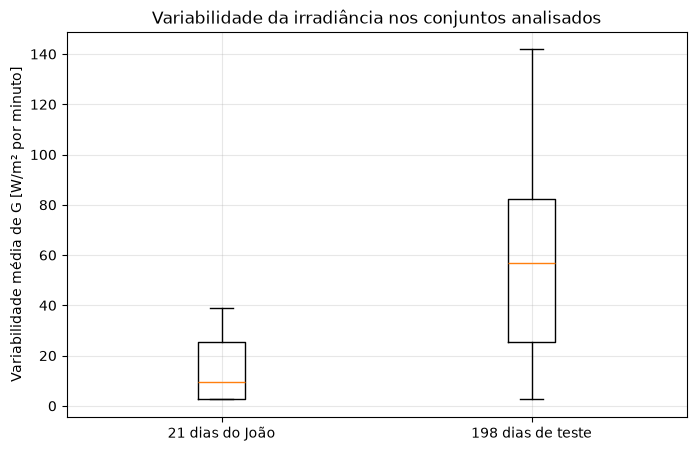

In [101]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    [
        df_variabilidade_21["VI_G"].dropna(),
        df_variabilidade["VI_G"].dropna()
    ],
    tick_labels=[
        "21 dias do João",
        "198 dias de teste"
    ]
)

plt.ylabel("Variabilidade média de G [W/m² por minuto]")
plt.title("Variabilidade da irradiância nos conjuntos analisados")
plt.grid(alpha=0.3)

plt.show()


In [102]:
df_21_variabilidade_erro = (
    df_metricas_21
    .join(df_variabilidade_21)
)

df_21_variabilidade_erro[
    ["nRMSE_%", "VI_G"]
].sort_values("VI_G")

,nRMSE_%,VI_G
Data,,
2019-05-25,2.436776,2.561353
2019-05-26,2.194313,2.585665
2019-07-16,2.416950,2.588108
2019-06-05,2.344161,2.599801
2019-08-22,2.280709,2.755548
2019-05-06,2.645106,2.773795
2019-07-17,2.387776,3.396827
2019-05-07,2.815133,3.769086
2019-08-01,4.053578,7.595659


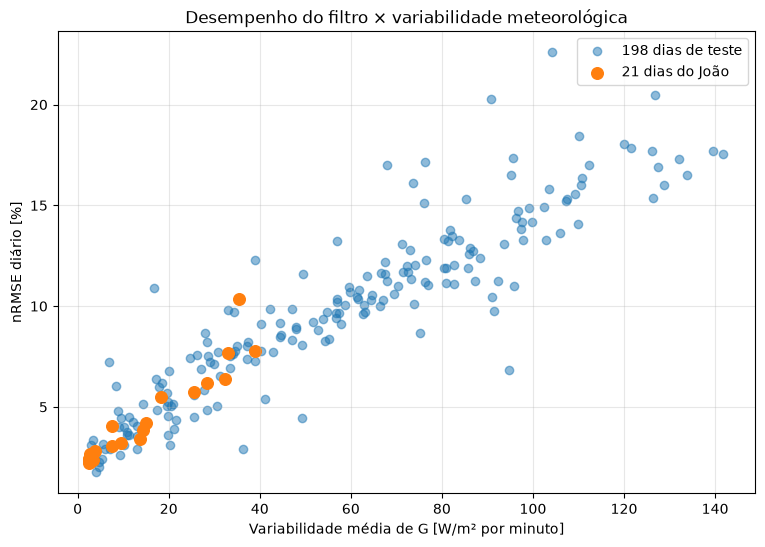

In [103]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df_analise_variabilidade["VI_G"],
    df_analise_variabilidade["nRMSE_%"],
    alpha=0.5,
    label="198 dias de teste"
)

plt.scatter(
    df_21_variabilidade_erro["VI_G"],
    df_21_variabilidade_erro["nRMSE_%"],
    s=70,
    label="21 dias do João"
)

plt.xlabel("Variabilidade média de G [W/m² por minuto]")
plt.ylabel("nRMSE diário [%]")
plt.title("Desempenho do filtro × variabilidade meteorológica")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [104]:
# ============================================================
# 41. FUNÇÃO CORRIGIDA DE VARIABILIDADE MINUTO A MINUTO
# ============================================================

def calcular_vi_g(df_dia, g_min=300):

    df_aux = df_dia[["G"]].copy()

    # Diferença usando a série temporal original
    df_aux["Delta_G"] = df_aux["G"].diff().abs()

    # G anterior
    df_aux["G_anterior"] = df_aux["G"].shift(1)

    # Só usamos pares consecutivos válidos
    mask = (
        df_aux["G"].notna() &
        df_aux["G_anterior"].notna() &
        (df_aux["G"] >= g_min) &
        (df_aux["G_anterior"] >= g_min)
    )

    return df_aux.loc[mask, "Delta_G"].mean()

In [105]:
# ============================================================
# 42. RECÁLCULO DO VI - 21 DIAS
# ============================================================

vi_21_corrigido = []

for data in DIAS_JOAO:

    df_dia = df_full.loc[
        data.strftime("%Y-%m-%d")
    ].copy()

    vi = calcular_vi_g(
        df_dia,
        g_min=300
    )

    vi_21_corrigido.append({
        "Data": data.date(),
        "VI_G": vi
    })

df_vi_21_corrigido = (
    pd.DataFrame(vi_21_corrigido)
    .set_index("Data")
)

In [107]:
# ============================================================
# 43. RECÁLCULO DO VI - 198 DIAS
# ============================================================

vi_teste_corrigido = []

for data in dias_teste_validos:

    df_dia = df_full.loc[
        data.strftime("%Y-%m-%d")
    ].copy()

    vi = calcular_vi_g(
        df_dia,
        g_min=300
    )

    vi_teste_corrigido.append({
        "Data": data.date(),
        "VI_G": vi
    })

df_vi_teste_corrigido = (
    pd.DataFrame(vi_teste_corrigido)
    .set_index("Data")
)

In [108]:
print("21 dias:")
display(
    df_vi_21_corrigido["VI_G"].describe()
)

print("\n198 dias:")
display(
    df_vi_teste_corrigido["VI_G"].describe()
)

21 dias:


count    21.000000
mean     14.105138
std      12.548700
min       2.561353
25%       2.773795
50%       9.431606
75%      22.612608
max      37.773646
Name: VI_G, dtype: float64


198 dias:


count    198.000000
mean      55.048824
std       35.864585
min        2.653969
25%       24.167956
50%       54.263027
75%       80.791087
max      142.708159
Name: VI_G, dtype: float64

In [109]:
df_variabilidade_corrigida = (
    df_metricas_teste
    .join(df_vi_teste_corrigido)
)

pearson = (
    df_variabilidade_corrigida[
        ["VI_G", "nRMSE_%"]
    ]
    .corr(method="pearson")
    .loc["VI_G", "nRMSE_%"]
)

spearman = (
    df_variabilidade_corrigida[
        ["VI_G", "nRMSE_%"]
    ]
    .corr(method="spearman")
    .loc["VI_G", "nRMSE_%"]
)

print(f"Pearson corrigido : {pearson:.4f}")
print(f"Spearman corrigido: {spearman:.4f}")

Pearson corrigido : 0.9154
Spearman corrigido: 0.9310


In [110]:
limite_vi = (
    df_vi_21_corrigido["VI_G"]
    .quantile(0.75)
)

print(
    f"Limite P75 dos 21 dias: {limite_vi:.3f}"
)

Limite P75 dos 21 dias: 22.613


In [111]:
dias_baixa_variabilidade = (
    df_vi_teste_corrigido[
        df_vi_teste_corrigido["VI_G"] <= limite_vi
    ]
    .index
)

print(
    "Dias de teste com variabilidade comparável:",
    len(dias_baixa_variabilidade)
)

Dias de teste com variabilidade comparável: 48


In [112]:
df_comp_teste["Data_aux"] = df_comp_teste.index.date

mask_vi_equivalente = (
    df_comp_teste["Data_aux"]
    .isin(dias_baixa_variabilidade)
)

df_comp_vi_equivalente = (
    df_comp_teste.loc[
        mask_vi_equivalente
    ]
    .copy()
)

In [113]:
metricas_vi_equivalente = calcular_metricas(
    df_comp_vi_equivalente["P_Real"],
    df_comp_vi_equivalente["P_Filtro"]
)

pd.Series(metricas_vi_equivalente)

N             24273.000000
P_media_kW     1565.913797
RMSE_kW          68.512938
nRMSE_%           4.375269
nMAE_%            2.669947
nMBE_%            0.065275
R2                0.974269
STDratio          1.045385
dtype: float64

In [114]:
# ============================================================
# 44. DIAS EXTERNOS COM VARIABILIDADE COMPARÁVEL
# ============================================================

limite_vi = (
    df_vi_21_corrigido["VI_G"]
    .quantile(0.75)
)

dias_baixa_variabilidade = (
    df_vi_teste_corrigido[
        df_vi_teste_corrigido["VI_G"] <= limite_vi
    ]
    .index
)

print(f"Limite de VI (P75 dos 21 dias): {limite_vi:.3f}")
print(
    "Dias externos com variabilidade comparável:",
    len(dias_baixa_variabilidade)
)

Limite de VI (P75 dos 21 dias): 22.613
Dias externos com variabilidade comparável: 48


In [115]:
# ============================================================
# 45. MÉTRICAS NOS DIAS EXTERNOS DE BAIXA VARIABILIDADE
# ============================================================

df_comp_teste_aux = df_comp_teste.copy()

df_comp_teste_aux["Data_aux"] = (
    df_comp_teste_aux.index.date
)

mask_vi_equivalente = (
    df_comp_teste_aux["Data_aux"]
    .isin(dias_baixa_variabilidade)
)

df_comp_vi_equivalente = (
    df_comp_teste_aux.loc[
        mask_vi_equivalente
    ]
    .copy()
)

metricas_vi_equivalente = calcular_metricas(
    df_comp_vi_equivalente["P_Real"],
    df_comp_vi_equivalente["P_Filtro"]
)

pd.Series(metricas_vi_equivalente)

N             24273.000000
P_media_kW     1565.913797
RMSE_kW          68.512938
nRMSE_%           4.375269
nMAE_%            2.669947
nMBE_%            0.065275
R2                0.974269
STDratio          1.045385
dtype: float64

In [116]:
pd.Series(metricas_vi_equivalente)

N             24273.000000
P_media_kW     1565.913797
RMSE_kW          68.512938
nRMSE_%           4.375269
nMAE_%            2.669947
nMBE_%            0.065275
R2                0.974269
STDratio          1.045385
dtype: float64

In [117]:
print(
    "Número de dias externos com VI comparável:",
    len(dias_baixa_variabilidade)
)

Número de dias externos com VI comparável: 48


In [118]:
# ============================================================
# 46. RESUMO FINAL DOS CENÁRIOS DO FILTRO
# ============================================================

resumo_filtro = pd.DataFrame({

    "21 dias do João":
        metricas_filtro_21,

    "Externos com VI comparável":
        metricas_vi_equivalente,

    "198 dias externos":
        metricas_filtro_teste

}).T

colunas_resumo = [
    "N",
    "P_media_kW",
    "RMSE_kW",
    "nRMSE_%",
    "nMAE_%",
    "nMBE_%",
    "R2",
    "STDratio"
]

resumo_filtro = resumo_filtro[colunas_resumo]

resumo_filtro

,N,P_media_kW,RMSE_kW,nRMSE_%,nMAE_%,nMBE_%,R2,STDratio
21 dias do João,10711.0,1618.890104,71.409934,4.411043,2.735269,-0.712940,0.975300,1.047027
Externos com VI comparável,24273.0,1565.913797,68.512938,4.375269,2.669947,0.065275,0.974269,1.045385
198 dias externos,92215.0,1501.974610,152.389255,10.145928,5.862740,-0.045733,0.900589,1.030836


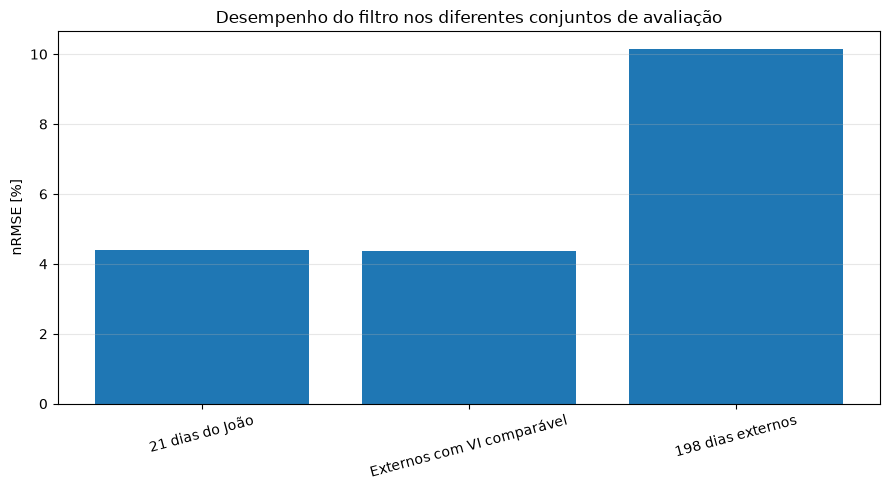

In [119]:
plt.figure(figsize=(9, 5))

plt.bar(
    resumo_filtro.index,
    resumo_filtro["nRMSE_%"]
)

plt.ylabel("nRMSE [%]")
plt.title("Desempenho do filtro nos diferentes conjuntos de avaliação")

plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [120]:
# ============================================================
# 46. RESUMO FINAL DOS CENÁRIOS DO FILTRO
# ============================================================

resumo_filtro = pd.DataFrame({

    "21 dias do João":
        metricas_filtro_21,

    "48 dias externos - VI comparável":
        metricas_vi_equivalente,

    "198 dias externos":
        metricas_filtro_teste

}).T

colunas_resumo = [
    "N",
    "P_media_kW",
    "RMSE_kW",
    "nRMSE_%",
    "nMAE_%",
    "nMBE_%",
    "R2",
    "STDratio"
]

resumo_filtro = resumo_filtro[colunas_resumo]

resumo_filtro

,N,P_media_kW,RMSE_kW,nRMSE_%,nMAE_%,nMBE_%,R2,STDratio
21 dias do João,10711.0,1618.890104,71.409934,4.411043,2.735269,-0.712940,0.975300,1.047027
48 dias externos - VI comparável,24273.0,1565.913797,68.512938,4.375269,2.669947,0.065275,0.974269,1.045385
198 dias externos,92215.0,1501.974610,152.389255,10.145928,5.862740,-0.045733,0.900589,1.030836
